# Student Feedback Sentiment Analysis

This notebook builds a 3-class sentiment classifier (negative / neutral / positive) for student course and teacher reviews. The pipeline is:

1. Load and inspect the raw dataset
2. Clean and normalise the text (including negation handling)
3. Explore the data visually (word cloud, top words per sentiment, class balance)
4. Split into train / validation / test sets and balance the training set (SMOTE for TF-IDF models, oversampling and augmentation for transformers)
5. Baselines: **VADER** (lexicon), **Multinomial Naive Bayes**, **Logistic Regression** and **Linear SVM** (TF-IDF)
6. **Leak-free cross-validation** of Logistic Regression and Linear SVM, with SMOTE applied inside each fold
7. Fine-tune two transformers: **DistilBERT** and sentiment-pretrained **RoBERTa**
8. Combine the strongest models in a soft-voting **ensemble**
9. Audit label noise and compare every model on accuracy and macro F1


##Install packages

In [ ]:
!pip install -q wordcloud vaderSentiment imbalanced-learn
!pip install -q --upgrade transformers accelerate datasets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 105.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 47.9 MB/s eta 0:00:00


In [ ]:
# Core
import re
import random
import numpy as np
import pandas as pd

# plot code
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS

# Natural language toolkit download
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# ML-logistic regression,naiye bayes, and linear regression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_fscore_support
)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# VADER
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

print(f"Torch: {torch.__version__} | Torchvision: {torchvision.__version__}")


Torch: 2.11.0+cu128 | Torchvision: 0.26.0+cu128


## Connect to Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Uploading dataset

A quick first look: column names, row count, and how the sentiment/aspect labels are distributed. Worth checking this every run, since a silent schema change upstream (e.g. a column renamed) will break everything downstream.

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Project/Dataset.csv")

print(df.columns.tolist())
print("Rows:", len(df))
print("\nSentiment distribution:")
print(df['sentiment_label'].value_counts())
print("\nAspect distribution:")
print(df['aspect'].value_counts())

df.sample(200, random_state=42).reset_index(drop=True).head()


['text', 'sentiment_label', 'aspect', 'label_source', 'source', 'domain']
Rows: 44516

Sentiment distribution:
sentiment_label
positive    27541
negative    12165
neutral      4810
Name: count, dtype: int64

Aspect distribution:
aspect
teaching              37562
teacher review         2995
course review          2946
university review       500
coursecontent           113
examination             103
labwork                 101
library_facilities      100
extracurricular          96
Name: count, dtype: int64


,text,sentiment_label,aspect,label_source,source,domain
0,Prof Mendle is one of the best professors in t...,positive,teaching,derived,rmp_oregon,instructor_review
1,Lecture Heavy. Only 4 graded projects and 2 mi...,positive,teaching,derived,rmp_oregon,instructor_review
2,Mr. Clementi is 23 and understands the struggle,positive,teaching,derived,rmp_oregon,instructor_review
3,I found Spike's class to be really interesting...,positive,teaching,derived,rmp_oregon,instructor_review
4,"Love her! She is an amazing teacher, she makes...",positive,teaching,derived,rmp_oregon,instructor_review


## Clean and normalize the text

Raw reviews are noisy — URLs, HTML fragments, inconsistent casing, stretched-out words ("sooooo good"). Before tokenizing we:

- lowercase everything and strip URLs/HTML/punctuation
- collapse repeated letters (`coooool` → `cool`)
- tokenize with NLTK
- **tag negation**: the 5 tokens following "not"/"never"/"no"/"without"/"n't" get a `_NEG` suffix, so "not helpful" doesn't get collapsed into the same bucket as "helpful". This has to happen *before* stopword removal, otherwise "not" gets stripped before it can tag anything.
- remove stopwords, but keep domain-relevant terms (module, lecturer, assignment, feedback) that NLTK would otherwise treat as noise
- lemmatize what's left

The result is stored in a new `text_clean` column.

In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

domain_keep = {'module', 'lecturer', 'assignment', 'feedback'}
stop_words = stop_words - domain_keep

negation_terms = {'not', 'never', 'no', 'without', 'nor'}
NEGATION_WINDOW = 5

def negate_tokens(tokens):
    """Append _NEG to each token within a 5-word window after a negation term.
    e.g. ['not', 'very', 'helpful'] -> ['not', 'very_NEG', 'helpful_NEG']
    """
    result = []
    neg_counter = 0
    for tok in tokens:
        if tok in negation_terms or tok.endswith("n't"):
            neg_counter = NEGATION_WINDOW
            result.append(tok)
            continue
        if neg_counter > 0:
            result.append(tok + "_NEG")
            neg_counter -= 1
        else:
            result.append(tok)
    return result

def preprocess_text(s):
    if pd.isna(s):
        return ""
    s = str(s)
    s = s.replace('\n', ' ').replace('\r', ' ')
    s = re.sub(r'http\S+|www\.\S+', ' ', s)
    s = re.sub(r'<[^>]+>', ' ', s)
    s = s.lower()
    s = re.sub(r'(.)\1{2,}', r'\1\1', s)
    s = re.sub(r"[^a-z0-9'\s]", ' ', s)  # keep apostrophes so n't survives
    s = re.sub(r'\s+', ' ', s).strip()

    tokens = word_tokenize(s)
    tokens = negate_tokens(tokens)

    cleaned_tokens = []
    for tok in tokens:
        is_neg = tok.endswith('_NEG')
        base = tok[:-4] if is_neg else tok
        if base in stop_words:
            continue
        lemma = lemmatizer.lemmatize(base)
        cleaned_tokens.append(lemma + '_NEG' if is_neg else lemma)

    return ' '.join(cleaned_tokens)

df['text_clean'] = df['text'].apply(preprocess_text)
df[['text', 'text_clean']].sample(5, random_state=1)


,text,text_clean
30000,I would encourage all students to take this co...,would encourage student take course thoroughly...
12952,"Terrible flake, no humor.",terrible flake humor_NEG
17706,If you have not taken CS 122 you will fail thi...,taken_NEG c_NEG 122_NEG fail class taken c 122...
28307,"She is a very nice person, but an awful lectur...",nice person awful lecturer place material real...
38623,Did not understand anything he taught us. Supe...,understand_NEG anything_NEG taught_NEG u_NEG s...


## Normalizimg sentiment labels

In this block of code different source datasets spell labels differently ('pos', 'good', 'excellent' all mean positive). This maps every variant onto a single `label_norm` column.

In [ ]:
label_map = {
    'positive': 'positive', 'pos': 'positive', 'good': 'positive', 'excellent': 'positive',
    'negative': 'negative', 'neg': 'negative',
    'neutral': 'neutral', 'avg': 'neutral', 'average': 'neutral'
}

def normalize_label(l):
    if pd.isna(l):
        return None
    return label_map.get(str(l).strip().lower(), str(l).strip().lower())

df['label_norm'] = df['sentiment_label'].apply(normalize_label)
df['label_norm'].value_counts()


,count
label_norm,
positive,27541
negative,12165
neutral,4810


## Screenshot code for Updation



In [ ]:
df[['text', 'text_clean', 'sentiment_label', 'label_norm']].to_csv(
    "/content/drive/MyDrive/Project/cleaned_report.csv", index=False
)


## Word Cloud



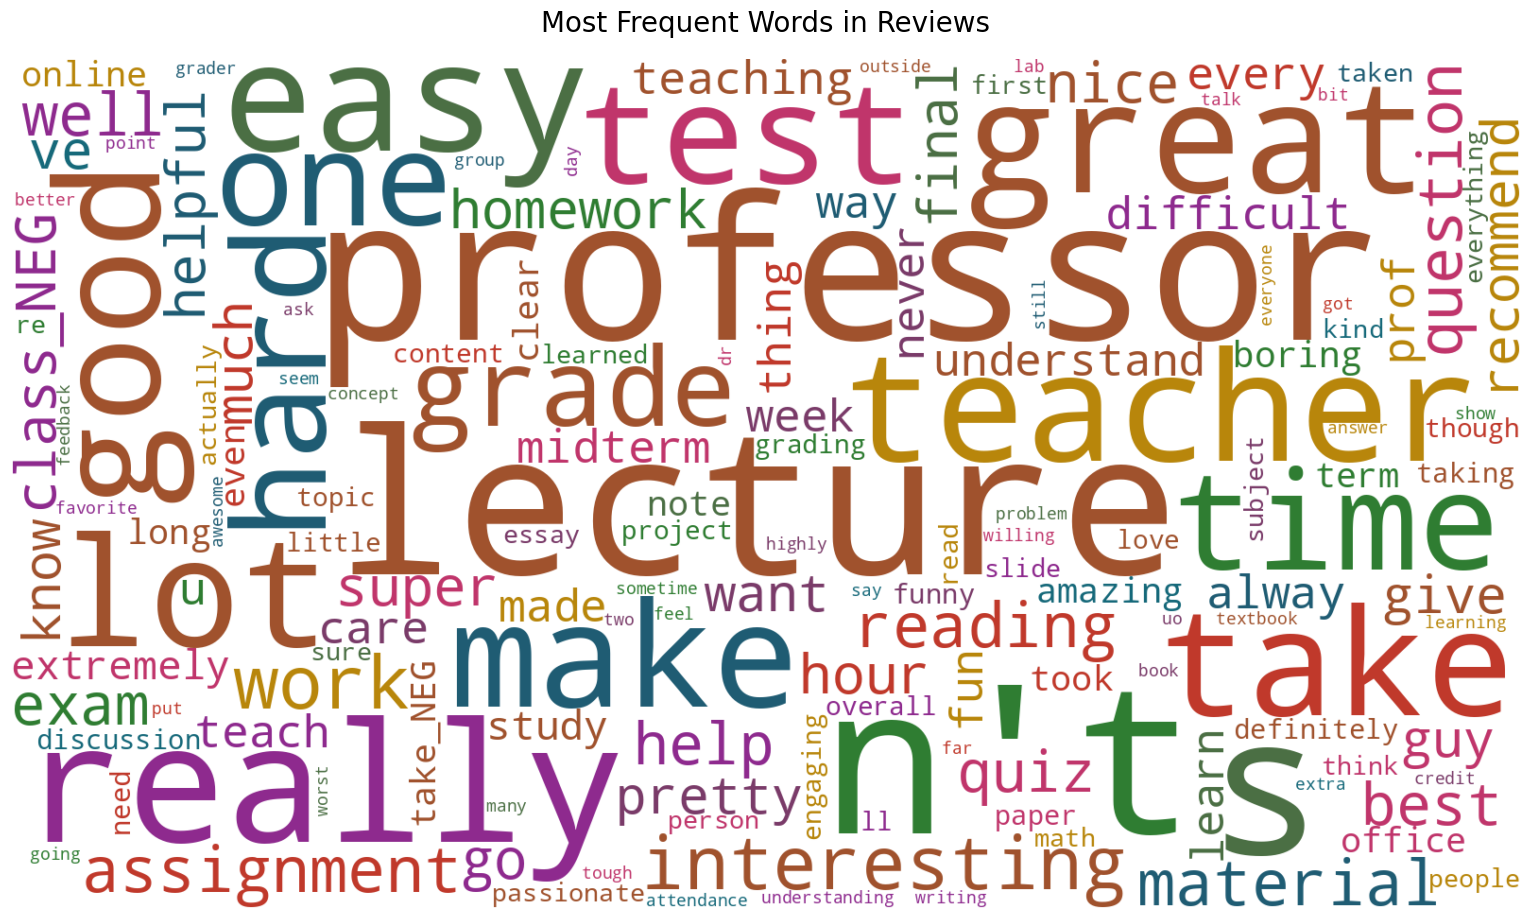

In [ ]:
all_text = " ".join(df['text_clean'].dropna().astype(str))

extra_stopwords = {"student", "students", "class", "course"}
wc_stopwords = STOPWORDS.union(extra_stopwords)

palette = [
    "#1f5c73", "#c0356b", "#2f7d32", "#b8860b", "#8e2a8e",
    "#c0392b", "#16697a", "#a0522d", "#4b6f44", "#7a3b69",
]

def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
    return random.choice(palette)

wc = WordCloud(
    width=1600, height=900, background_color="white",
    stopwords=wc_stopwords, prefer_horizontal=0.85, relative_scaling=0.5,
    min_font_size=10, max_font_size=220, collocations=False,
    max_words=150, color_func=color_func,
).generate(all_text)

plt.figure(figsize=(16, 9))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Reviews", size=20, pad=20)
plt.tight_layout(pad=0)
plt.show()

wc.to_file("/content/drive/MyDrive/Project/wordcloud.png")


## Word graph in each class label

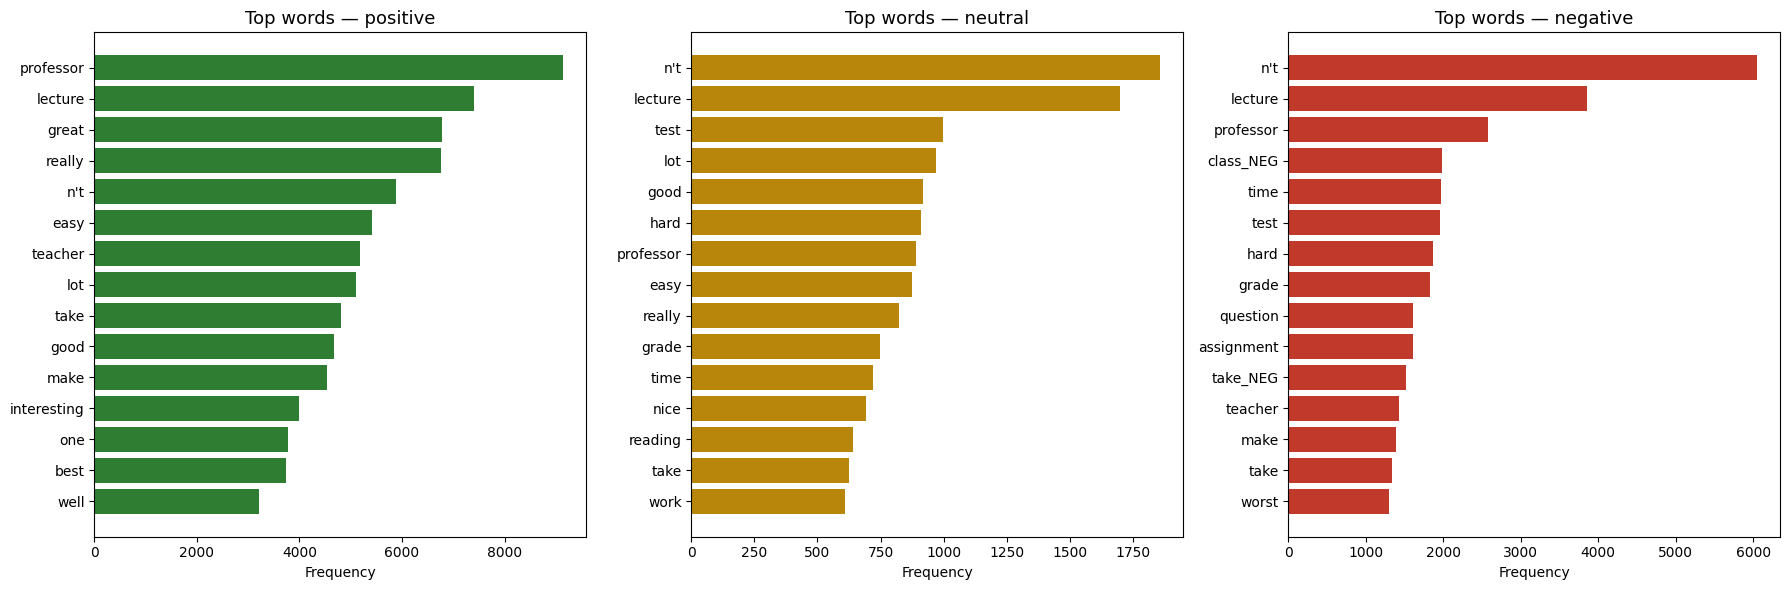

In [ ]:
from collections import Counter

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = {'positive': '#2f7d32', 'neutral': '#b8860b', 'negative': '#c0392b'}

for ax, sentiment in zip(axes, ['positive', 'neutral', 'negative']):
    text = " ".join(df.loc[df['label_norm'] == sentiment, 'text_clean'].dropna().astype(str))
    words = [w for w in text.split() if w not in wc_stopwords and len(w) > 2]
    top_words = Counter(words).most_common(15)
    labels, counts = zip(*top_words) if top_words else ([], [])

    ax.barh(labels[::-1], counts[::-1], color=colors[sentiment])
    ax.set_title(f"Top words — {sentiment}", fontsize=13)
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/top_words_by_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()


**Why aren't the overlapping words (e.g. "lecture", "professor", "n't") removed from these charts?**

It's tempting to look at the three panels above, see the same handful of words repeating, and manually filter them out to "clean up" the chart or hoping it improves accuracy. We don't do that here, for a few reasons:

- **Frequency isn't the same thing as signal.** A word appearing often in all three classes just means it's part of the shared topic vocabulary (this is a dataset about lectures/professors, after all). What actually lets the model tell classes apart is the *relative* frequency and context of a word across classes — not whether the word is exclusive to one class. TF-IDF already down-weights words that appear everywhere, and DistilBERT learns this distinction from context automatically. Hand-deleting "common" words from a bar chart would be redundant with what the models already do — or worse, it would throw away real signal.
- **`n't` is a good example of why this matters.** It shows up as a top word in *neutral* and *negative* but ranks lower in *positive* — that gap is genuinely informative (negation correlates with negative/neutral sentiment). If we deleted every word that repeats across panels, we'd delete this one too, along with the useful signal it carries.
- **This chart is exploratory, not a feature-selection step.** Its job is to show what people are actually writing about per class, not to hand-pick the model's vocabulary. Stopword removal already happened earlier in preprocessing (`stop_words` in the cleaning cell) — that's the principled place to remove genuinely uninformative words, not here.


## Split into train / validation / test

70/10/20 split (train / validation / test), stratified on `label_norm` so each split keeps the same class proportions as the full dataset.

In [ ]:
train, test = train_test_split(df, test_size=0.2, stratify=df['label_norm'], random_state=42)
train, val = train_test_split(train, test_size=0.125, stratify=train['label_norm'], random_state=42)  # 0.125 * 0.8 = 10% of the full data

print(f"train={len(train)}  val={len(val)}  test={len(test)}")

train.to_csv("/content/drive/MyDrive/Project/train.csv", index=False)
val.to_csv("/content/drive/MyDrive/Project/val.csv", index=False)
test.to_csv("/content/drive/MyDrive/Project/test.csv", index=False)


train=31160  val=4452  test=8904


## Training set Balancing

The classes are heavily imbalanced (positive reviews dominate). Two different balancing techniques are needed here, because SMOTE oversamples *numeric feature vectors*, not raw sentences — it can't generate new real text for BERT to read.

- **SMOTE on TF-IDF vectors** — for classical vector-based models (Logistic Regression / SVM baselines). Produces genuinely synthetic minority-class vectors.
- **RandomOverSampler on raw rows** — duplicates real minority-class *sentences* so DistilBERT fine-tunes on actual text, not synthetic vectors.

In [ ]:
# --- SMOTE on TF-IDF vectors (classical models) ---
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(train['text_clean'])
y_train = train['label_norm']

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE :", pd.Series(y_train_smote).value_counts().to_dict())

# --- RandomOverSampler on raw rows (for DistilBERT) ---
ros = RandomOverSampler(random_state=42)
row_idx = np.arange(len(train)).reshape(-1, 1)
row_idx_resampled, _ = ros.fit_resample(row_idx, train['label_norm'])
train_balanced = train.iloc[row_idx_resampled.flatten()].reset_index(drop=True)

print("\nBefore oversampling:", train['label_norm'].value_counts().to_dict())
print("After oversampling :", train_balanced['label_norm'].value_counts().to_dict())

train_balanced.to_csv("/content/drive/MyDrive/Project/train_balanced.csv", index=False)


Before SMOTE: {'positive': 19278, 'negative': 8515, 'neutral': 3367}
After SMOTE : {'positive': 19278, 'negative': 19278, 'neutral': 19278}

Before oversampling: {'positive': 19278, 'negative': 8515, 'neutral': 3367}
After oversampling : {'positive': 19278, 'negative': 19278, 'neutral': 19278}


## Before vs. after SMOTE differentiation in Visualisation

The class-balance chart later in this notebook shows *counts* before/after oversampling, but that's for the `RandomOverSampler` path (raw duplicated sentences, used for DistilBERT). SMOTE works differently — it manufactures brand-new synthetic points in TF-IDF vector space, so it deserves its own before/after comparison.

Two views below:
- **Class counts**, before vs. after SMOTE specifically (not the ROS version)
- **A 2D projection** of the TF-IDF vectors (via `TruncatedSVD`, which — unlike PCA — works directly on sparse TF-IDF matrices), so you can actually see the minority classes go from a handful of scattered points to a dense, populated region after SMOTE fills the gaps in.

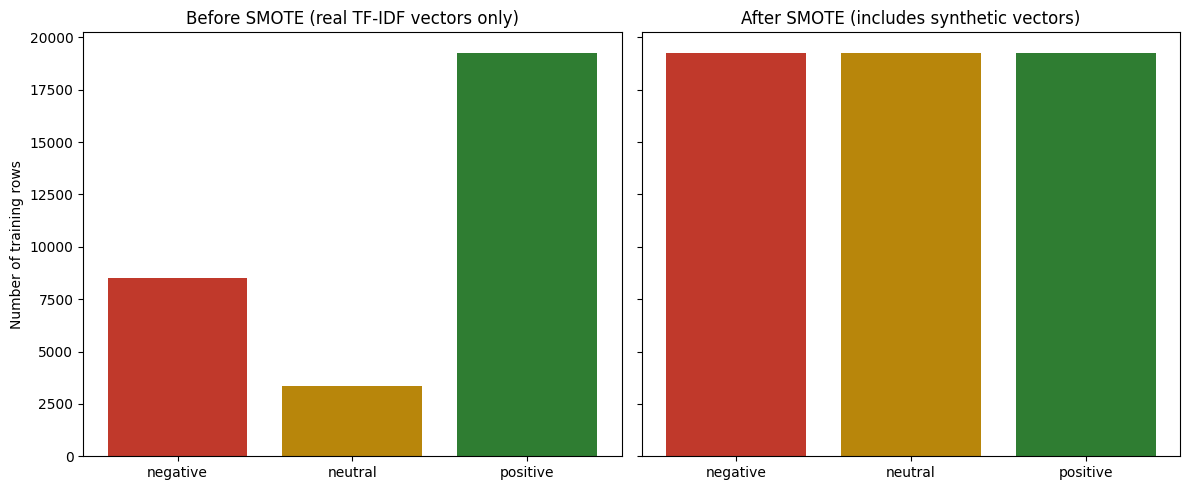

Variance explained by these 2 components: 0.8% (out of 5000 total TF-IDF dimensions)


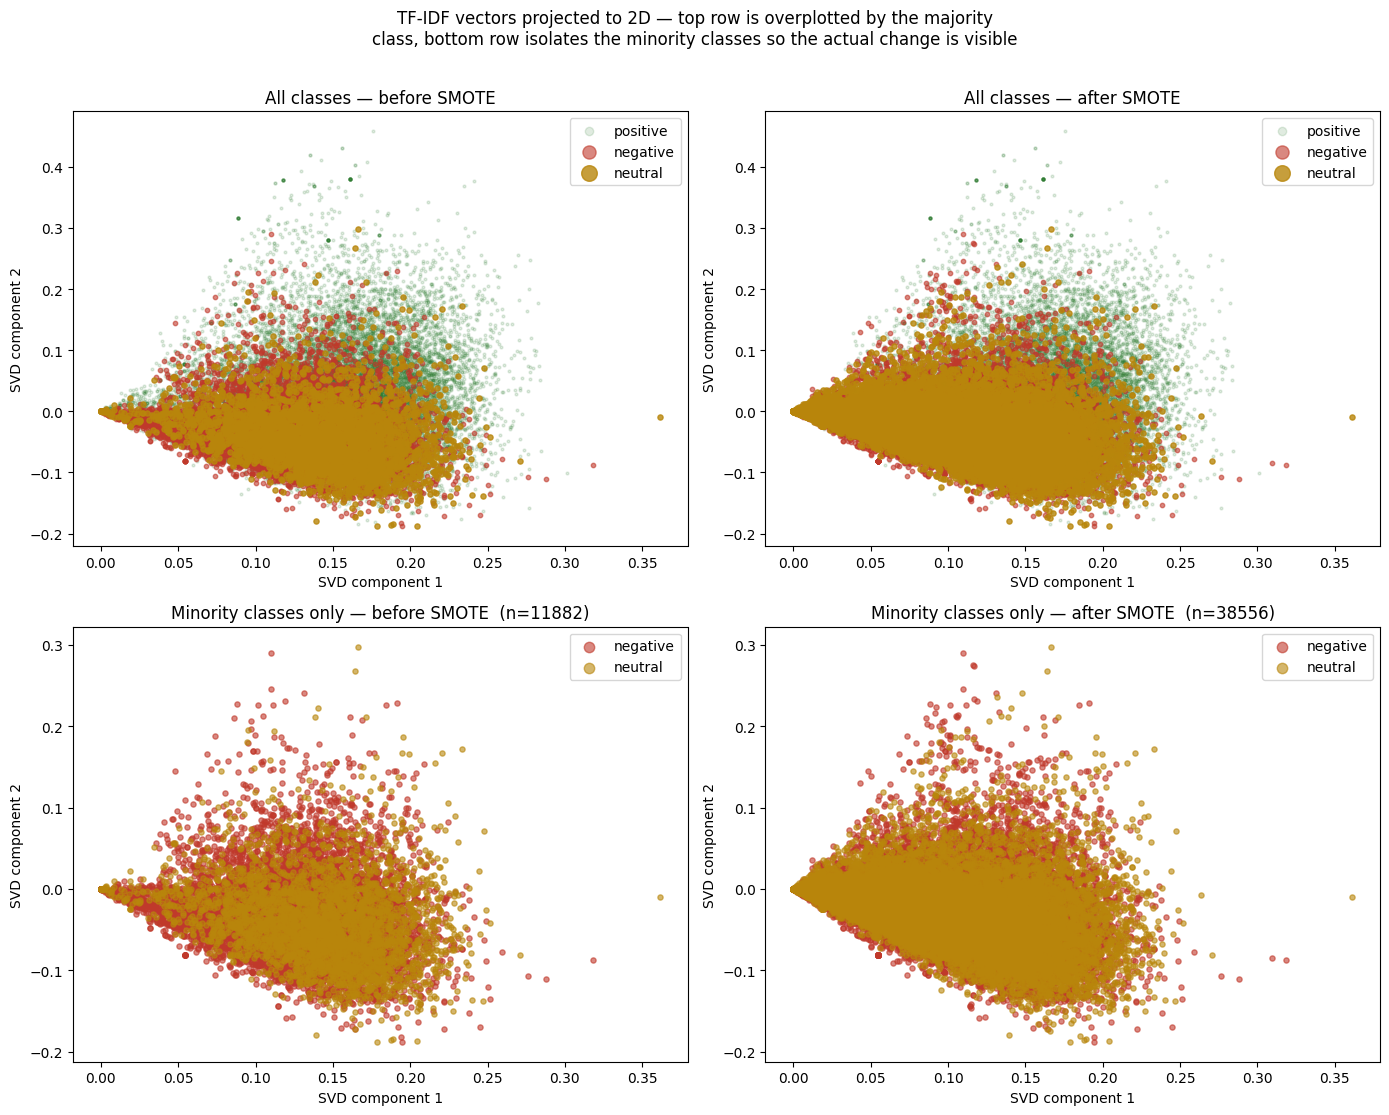

In [ ]:
# Class counts
before_smote_counts = y_train.value_counts().reindex(['negative', 'neutral', 'positive'])
after_smote_counts = pd.Series(y_train_smote).value_counts().reindex(['negative', 'neutral', 'positive'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
bar_colors = ['#c0392b', '#b8860b', '#2f7d32']

axes[0].bar(before_smote_counts.index, before_smote_counts.values, color=bar_colors)
axes[0].set_title("Before SMOTE (real TF-IDF vectors only)")
axes[0].set_ylabel("Number of training rows")

axes[1].bar(after_smote_counts.index, after_smote_counts.values, color=bar_colors)
axes[1].set_title("After SMOTE (includes synthetic vectors)")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/smote_class_counts.png", dpi=150, bbox_inches="tight")
plt.show()

# 2D projection of TF-IDF vectors
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)
before_2d = svd.fit_transform(X_train_tfidf)
after_2d = svd.transform(X_train_smote)

print(f"Variance explained by these 2 components: {svd.explained_variance_ratio_.sum():.1%}"
      f" (out of {X_train_tfidf.shape[1]} total TF-IDF dimensions)")

class_colors = {'negative': '#c0392b', 'neutral': '#b8860b', 'positive': '#2f7d32'}
y_train_smote_arr = np.array(y_train_smote)

# Majority class is drawn first, small and faded, so the minority classes stay visible on top
plot_order = ['positive', 'negative', 'neutral']
sizes = {'positive': 4, 'negative': 10, 'neutral': 14}
alphas = {'positive': 0.15, 'negative': 0.6, 'neutral': 0.8}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for label in plot_order:
    mask = (y_train.values == label)
    axes[0, 0].scatter(before_2d[mask, 0], before_2d[mask, 1], s=sizes[label],
                        alpha=alphas[label], color=class_colors[label], label=label)
axes[0, 0].set_title("All classes — before SMOTE")
axes[0, 0].legend(markerscale=3)

for label in plot_order:
    mask = (y_train_smote_arr == label)
    axes[0, 1].scatter(after_2d[mask, 0], after_2d[mask, 1], s=sizes[label],
                        alpha=alphas[label], color=class_colors[label], label=label)
axes[0, 1].set_title("All classes — after SMOTE")
axes[0, 1].legend(markerscale=3)

# Minority classes
for label in ['negative', 'neutral']:
    mask = (y_train.values == label)
    axes[1, 0].scatter(before_2d[mask, 0], before_2d[mask, 1], s=14,
                        alpha=0.6, color=class_colors[label], label=label)
axes[1, 0].set_title(f"Minority classes only — before SMOTE  (n={(y_train != 'positive').sum()})")
axes[1, 0].legend(markerscale=2)

for label in ['negative', 'neutral']:
    mask = (y_train_smote_arr == label)
    axes[1, 1].scatter(after_2d[mask, 0], after_2d[mask, 1], s=14,
                        alpha=0.6, color=class_colors[label], label=label)
n_minority_after = (y_train_smote_arr != 'positive').sum()
axes[1, 1].set_title(f"Minority classes only — after SMOTE  (n={n_minority_after})")
axes[1, 1].legend(markerscale=2)

for ax in axes.flat:
    ax.set_xlabel("SVD component 1")
    ax.set_ylabel("SVD component 2")

plt.suptitle("TF-IDF vectors projected to 2D — top row is overplotted by the majority\n"
             "class, bottom row isolates the minority classes so the actual change is visible",
             y=1.01)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/smote_2d_projection.png", dpi=150, bbox_inches="tight")
plt.show()


## Seeing the imbalance

Numbers in a dict are easy to skim past — a side-by-side chart makes it obvious just how skewed the raw training data is, and confirms the oversampling actually equalized it.

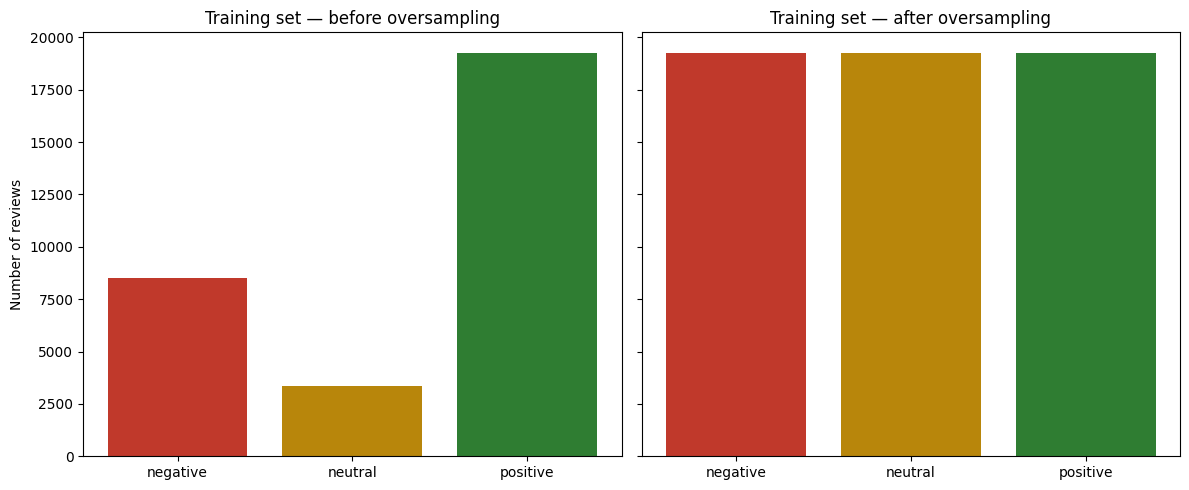

In [ ]:
before_counts = train['label_norm'].value_counts().reindex(['negative', 'neutral', 'positive'])
after_counts = train_balanced['label_norm'].value_counts().reindex(['negative', 'neutral', 'positive'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
bar_colors = ['#c0392b', '#b8860b', '#2f7d32']

axes[0].bar(before_counts.index, before_counts.values, color=bar_colors)
axes[0].set_title("Training set — before oversampling")
axes[0].set_ylabel("Number of reviews")

axes[1].bar(after_counts.index, after_counts.values, color=bar_colors)
axes[1].set_title("Training set — after oversampling")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/class_balance.png", dpi=150, bbox_inches="tight")
plt.show()


## Does oversampling change *what words* show up?

The chart above proves the row *counts* got balanced. It doesn't prove anything about vocabulary. Since `RandomOverSampler` works by duplicating whole rows (not generating new text), the word-frequency *shape* for a given class should look identical before and after — just scaled up. That's exactly what we'd want: DistilBERT should see more copies of the same real neutral/negative reviews, not some altered version of them. The chart below confirms that's actually what's happening, using the neutral class as the check.

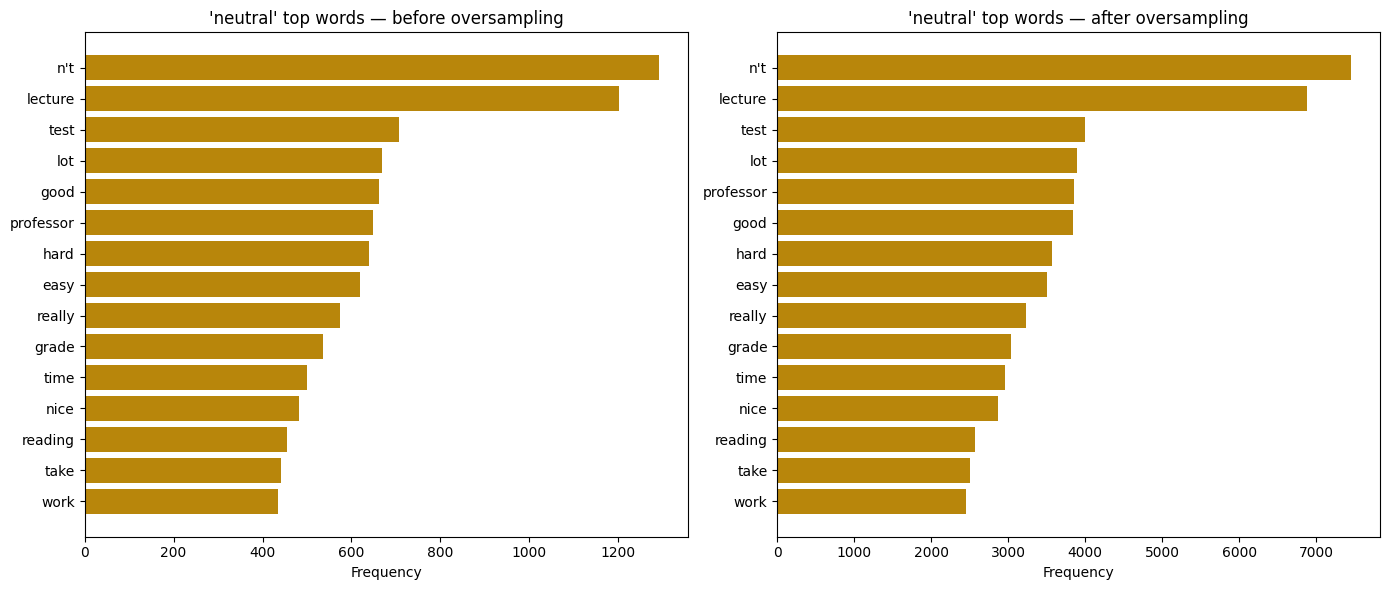

In [ ]:
check_class = 'neutral'

def top_words_for(frame, label, n=15):
    text = " ".join(frame.loc[frame['label_norm'] == label, 'text_clean'].dropna().astype(str))
    words = [w for w in text.split() if w not in wc_stopwords and len(w) > 2]
    return Counter(words).most_common(n)

before_top = top_words_for(train, check_class)
after_top = top_words_for(train_balanced, check_class)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=False)

labels_b, counts_b = zip(*before_top) if before_top else ([], [])
axes[0].barh(labels_b[::-1], counts_b[::-1], color='#b8860b')
axes[0].set_title(f"'{check_class}' top words — before oversampling")
axes[0].set_xlabel("Frequency")

labels_a, counts_a = zip(*after_top) if after_top else ([], [])
axes[1].barh(labels_a[::-1], counts_a[::-1], color='#b8860b')
axes[1].set_title(f"'{check_class}' top words — after oversampling")
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/vocab_before_after_oversampling.png", dpi=150, bbox_inches="tight")
plt.show()


##  VADER

VADER is a rule-based sentiment lexicon, no training required. It's a useful sanity-check baseline: any model we build should meaningfully beat it, not just match it.

In [ ]:
analyzer = SentimentIntensityAnalyzer()

def vader_label(text, pos_thr=0.05, neg_thr=-0.05):
    score = analyzer.polarity_scores(str(text))['compound']
    if score > pos_thr:
        return 'positive'
    elif score < neg_thr:
        return 'negative'
    else:
        return 'neutral'

df_test = pd.read_csv("/content/drive/MyDrive/Project/test.csv")
df_test = df_test.dropna(subset=["text_clean", "label_norm"]).reset_index(drop=True)
df_test['vader_pred'] = df_test['text_clean'].apply(vader_label)

vader_report = classification_report(df_test['label_norm'], df_test['vader_pred'], digits=4, output_dict=True)
print(classification_report(df_test['label_norm'], df_test['vader_pred'], digits=4))

vader_macro_f1 = f1_score(df_test['label_norm'], df_test['vader_pred'], average='macro')
vader_accuracy = vader_report['accuracy']
print("Macro F1:", vader_macro_f1)

              precision    recall  f1-score   support

    negative     0.7938    0.5127    0.6230      2432
     neutral     0.1070    0.0478    0.0661       962
    positive     0.7526    0.9430    0.8371      5508

    accuracy                         0.7287      8902
   macro avg     0.5511    0.5012    0.5088      8902
weighted avg     0.6941    0.7287    0.6953      8902

Macro F1: 0.5087530058197982


## 73% accuracy does tell the whole story?

VADER lands at **~72.9% accuracy** on the test set, which sounds solid at first glance. But accuracy alone hides a lot when classes are imbalanced — and here they really are: positive reviews make up roughly 62% of the test set. A model that *always* predicted "positive" and never looked at the text would already score ~61.9% accuracy. So VADER is only about **11 points better than guessing the majority class every time.**

The macro F1 score (0.51) makes this much clearer than accuracy does, because it treats all three classes equally instead of being dominated by whichever class has the most examples. The charts below break down exactly where VADER is winning and where it's failing:

- it's reasonably good at spotting clearly **positive** reviews (high recall)
- it's mediocre on **negative** reviews (misses about half of them)
- it's basically unable to detect **neutral** reviews (recall under 5%) — which is exactly why the accuracy number looks better than the model actually is: neutral is the smallest class, so getting it almost entirely wrong barely dents the overall accuracy score.

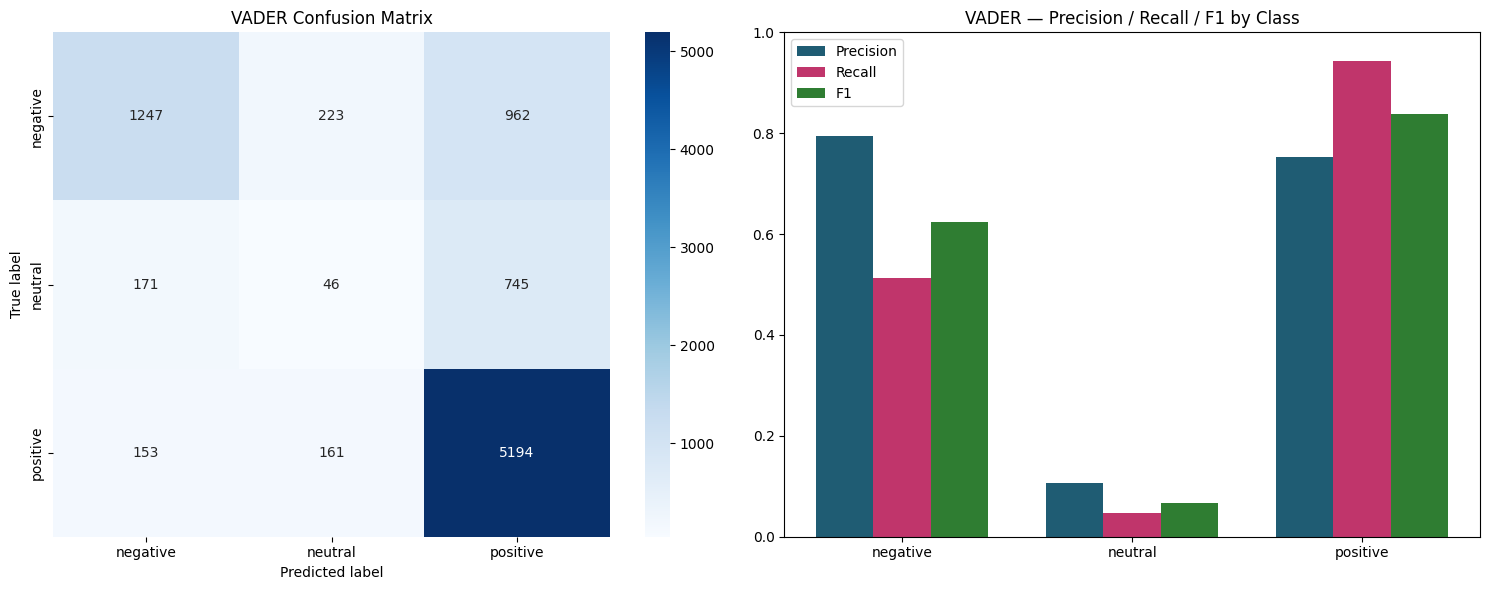

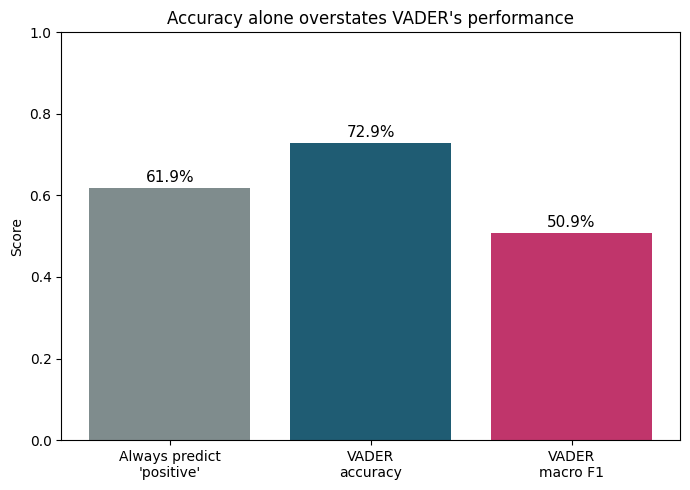

Majority-class baseline accuracy: 0.6187
VADER accuracy:                  0.7287
VADER macro F1:                  0.5088


In [ ]:
# Confusion matrix
labels_order = ['negative', 'neutral', 'positive']
cm = confusion_matrix(df_test['label_norm'], df_test['vader_pred'], labels=labels_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_order, yticklabels=labels_order, ax=axes[0])
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_title('VADER Confusion Matrix')

# Each class precision/recall/F1
prf = precision_recall_fscore_support(df_test['label_norm'], df_test['vader_pred'], labels=labels_order)
x = np.arange(len(labels_order))
width = 0.25
axes[1].bar(x - width, prf[0], width, label='Precision', color='#1f5c73')
axes[1].bar(x, prf[1], width, label='Recall', color='#c0356b')
axes[1].bar(x + width, prf[2], width, label='F1', color='#2f7d32')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_order)
axes[1].set_ylim(0, 1)
axes[1].set_title('VADER — Precision / Recall / F1 by Class')
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/vader_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Accuracy vs. a "just guess the majority class" baseline ---
majority_class = df_test['label_norm'].value_counts().idxmax()
naive_accuracy = (df_test['label_norm'] == majority_class).mean()

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    [f"Always predict\n'{majority_class}'", "VADER\naccuracy", "VADER\nmacro F1"],
    [naive_accuracy, vader_accuracy, vader_macro_f1],
    color=['#7f8c8d', '#1f5c73', '#c0356b']
)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Accuracy alone overstates VADER's performance")
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1%}", (bar.get_x() + bar.get_width() / 2, height),
                textcoords="offset points", xytext=(0, 4), ha='center', fontsize=11)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/vader_vs_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Majority-class baseline accuracy: {naive_accuracy:.4f}")
print(f"VADER accuracy:                  {vader_accuracy:.4f}")
print(f"VADER macro F1:                  {vader_macro_f1:.4f}")


## Multinomial Naive Bayes (TF-IDF)

VADER doesn't learn anything from our data, it's a fixed lexicon that never sees a single labeled example. Multinomial Naive Bayes is a step up from that, a simple, fast classical model that actually trains on the SMOTE-balanced TF-IDF vectors built earlier. It still won't handle context or word order the way DistilBERT can, but it's a much fairer comparison point for asking "is fine-tuning a transformer actually worth the extra training time?" than VADER alone is, if DistilBERT can't beat a five-second-to-train Naive Bayes model, that's a real problem worth knowing about.

              precision    recall  f1-score   support

    negative     0.7755    0.7743    0.7749      2432
     neutral     0.2506    0.5530    0.3449       962
    positive     0.9333    0.7373    0.8238      5508

    accuracy                         0.7275      8902
   macro avg     0.6532    0.6882    0.6479      8902
weighted avg     0.8165    0.7275    0.7587      8902



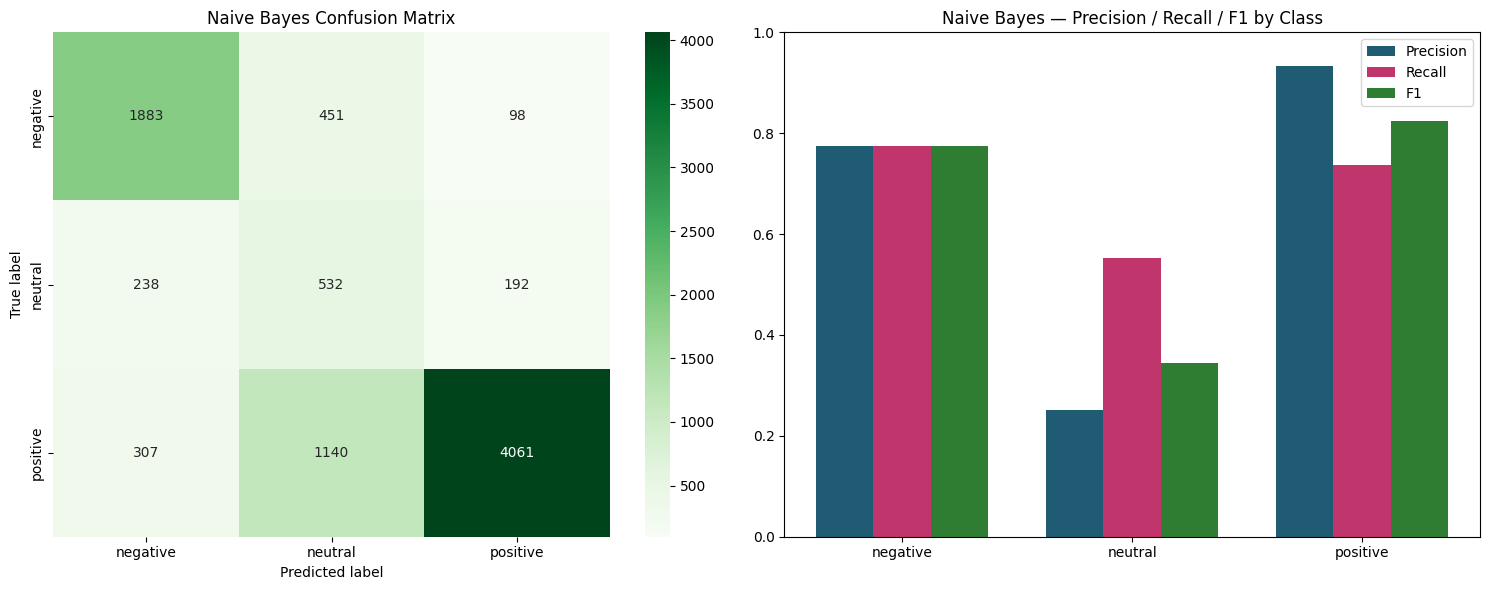

Naive Bayes accuracy: 0.7275
Naive Bayes macro F1: 0.6479


In [ ]:
nb_model = MultinomialNB()
nb_model.fit(X_train_smote, y_train_smote)

X_test_tfidf = tfidf.transform(df_test['text_clean'].fillna(''))
nb_pred = nb_model.predict(X_test_tfidf)

nb_report = classification_report(df_test['label_norm'], nb_pred, digits=4, output_dict=True)
print(classification_report(df_test['label_norm'], nb_pred, digits=4))

nb_accuracy = nb_report['accuracy']
nb_macro_f1 = f1_score(df_test['label_norm'], nb_pred, average='macro')

cm = confusion_matrix(df_test['label_norm'], nb_pred, labels=labels_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels_order, yticklabels=labels_order, ax=axes[0])
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_title('Naive Bayes Confusion Matrix')

prf = precision_recall_fscore_support(df_test['label_norm'], nb_pred, labels=labels_order)
x = np.arange(len(labels_order))
width = 0.25
axes[1].bar(x - width, prf[0], width, label='Precision', color='#1f5c73')
axes[1].bar(x, prf[1], width, label='Recall', color='#c0356b')
axes[1].bar(x + width, prf[2], width, label='F1', color='#2f7d32')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_order)
axes[1].set_ylim(0, 1)
axes[1].set_title('Naive Bayes — Precision / Recall / F1 by Class')
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/naive_bayes_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Naive Bayes accuracy: {nb_accuracy:.4f}")
print(f"Naive Bayes macro F1: {nb_macro_f1:.4f}")

## Logistic Regression and Linear SVM (TF-IDF)

Naive Bayes assumes every word is independent given the class, which is a real simplification for language. Logistic Regression and Linear SVM don't make that assumption, they can weight combinations of words more sensibly and on text classification tasks they typically edge out Naive Bayes by a few points. Both are trained on the same SMOTE-balanced TF-IDF vectors, so this is an apples-to-apples comparison, not a different setup.

Logistic Regression
              precision    recall  f1-score   support

    negative     0.7790    0.7944    0.7866      2432
     neutral     0.2665    0.3524    0.3035       962
    positive     0.8942    0.8361    0.8641      5508

    accuracy                         0.7724      8902
   macro avg     0.6466    0.6610    0.6514      8902
weighted avg     0.7949    0.7724    0.7824      8902


Linear SVM
              precision    recall  f1-score   support

    negative     0.7599    0.7887    0.7740      2432
     neutral     0.2584    0.2952    0.2756       962
    positive     0.8860    0.8491    0.8672      5508

    accuracy                         0.7727      8902
   macro avg     0.6348    0.6443    0.6389      8902
weighted avg     0.7837    0.7727    0.7778      8902



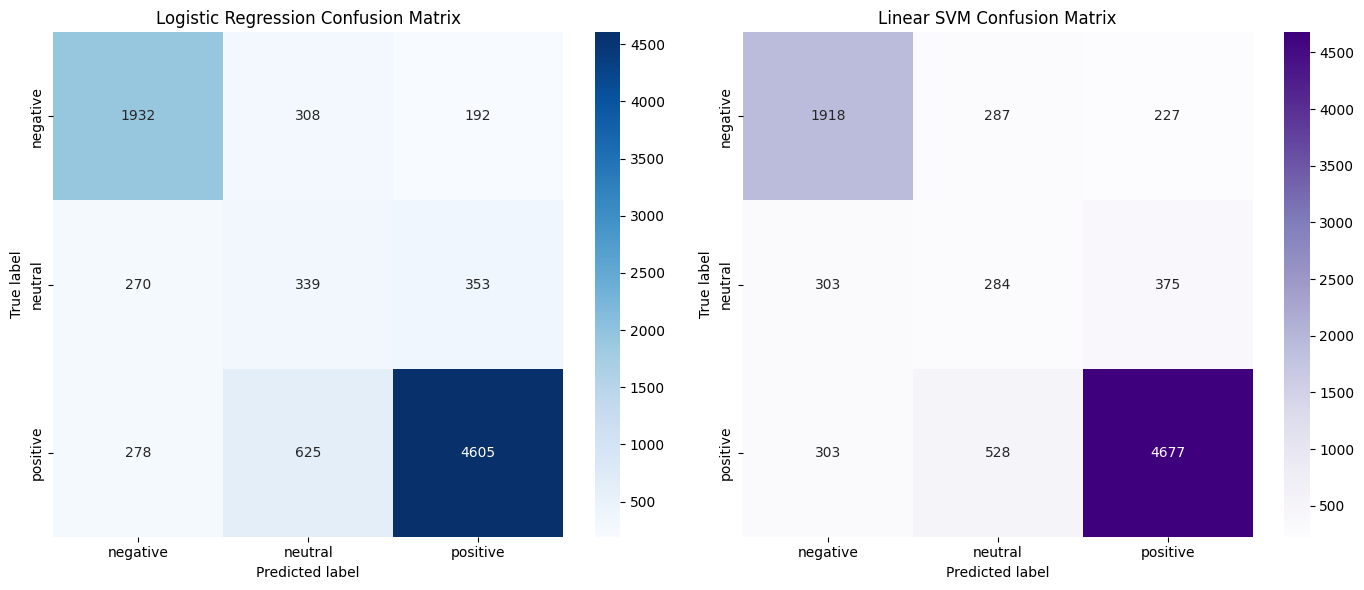


Logistic Regression — accuracy: 0.7724, macro F1: 0.6514
Linear SVM           — accuracy: 0.7727, macro F1: 0.6389


In [ ]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_smote, y_train_smote)
lr_pred = lr_model.predict(X_test_tfidf)

lr_report = classification_report(df_test['label_norm'], lr_pred, digits=4, output_dict=True)
print("Logistic Regression")
print(classification_report(df_test['label_norm'], lr_pred, digits=4))

lr_accuracy = lr_report['accuracy']
lr_macro_f1 = f1_score(df_test['label_norm'], lr_pred, average='macro')

# Linear SVM
svm_model = CalibratedClassifierCV(LinearSVC(class_weight='balanced', random_state=42))
svm_model.fit(X_train_smote, y_train_smote)
svm_pred = svm_model.predict(X_test_tfidf)

svm_report = classification_report(df_test['label_norm'], svm_pred, digits=4, output_dict=True)
print("\nLinear SVM")
print(classification_report(df_test['label_norm'], svm_pred, digits=4))

svm_accuracy = svm_report['accuracy']
svm_macro_f1 = f1_score(df_test['label_norm'], svm_pred, average='macro')

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, title, cmap in [(axes[0], lr_pred, 'Logistic Regression', 'Blues'),
                                (axes[1], svm_pred, 'Linear SVM', 'Purples')]:
    cm = confusion_matrix(df_test['label_norm'], pred, labels=labels_order)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, xticklabels=labels_order, yticklabels=labels_order, ax=ax)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(f'{title} Confusion Matrix')

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/lr_svm_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nLogistic Regression — accuracy: {lr_accuracy:.4f}, macro F1: {lr_macro_f1:.4f}")
print(f"Linear SVM           — accuracy: {svm_accuracy:.4f}, macro F1: {svm_macro_f1:.4f}")


## Cross-validating Logistic Regression and Linear SVM (without SMOTE leakage)

Every number so far comes from a single train/test split, so five-fold cross-validation is used to check how stable the two strongest classical models are.

The simple approach is to run `cross_val_score` on `X_train_smote`, the data that has *already* been through SMOTE. That produces an inflated score for two reasons:

- **Synthetic points leak across folds.** SMOTE creates each new minority sample by interpolating between a real review and one of its nearest neighbours. When SMOTE runs before the split, a synthetic point can land in a training fold while the real reviews it was built from sit in the validation fold. The model is then effectively tested on near-copies of data it has already seen, which is the "doubled data" problem.
- **The validation folds are artificially balanced.** After SMOTE every class has 19,278 rows, so each validation fold is one-third neutral. Real data is only about 11% neutral, and neutral is the hardest class, so this also flatters macro F1.

The earlier version of this cell did exactly that and reported a CV macro F1 of **0.792**, while the same Logistic Regression scored only **0.651** on the real test set. A gap that large is a sign of leakage, not of a lucky test split.

**The fix.** The TF-IDF vectoriser, SMOTE and the classifier are wrapped in a single `imblearn` pipeline and cross-validated on the original, unbalanced training text. In each fold:

1. TF-IDF is fitted on the four training folds only
2. SMOTE oversamples those four folds only
3. The model is scored on the untouched fifth fold, which keeps the real class distribution and contains no synthetic rows

`imblearn`'s pipeline applies SMOTE during `fit` and skips it during prediction, which is what makes this work. The leaky version is also run on both models so the difference can be seen directly.


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_cv = train['text_clean'].fillna('')
y_cv = train['label_norm']

def make_cv_model(name):
    if name == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    return CalibratedClassifierCV(LinearSVC(class_weight='balanced', random_state=42))

def make_leak_free_pipeline(name):
    return ImbPipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('smote', SMOTE(random_state=42)),
        ('clf', make_cv_model(name)),
    ])

scoring = {'accuracy': 'accuracy', 'macro_f1': 'f1_macro'}
cv_rows = []
cv_fold_scores = {}

for name in ['Logistic Regression', 'Linear SVM']:
    # Leaky: CV on data that was already SMOTE-balanced before splitting
    leaky = cross_validate(make_cv_model(name), X_train_smote, y_train_smote,
                           cv=skf, scoring=scoring, n_jobs=-1)

    # Leak-free: TF-IDF and SMOTE are refitted inside each training fold only
    clean = cross_validate(make_leak_free_pipeline(name), X_cv, y_cv,
                           cv=skf, scoring=scoring, n_jobs=-1)
    cv_fold_scores[name] = clean['test_macro_f1']

    for setup, res in [('Leaky (SMOTE before split)', leaky), ('Leak-free (SMOTE inside folds)', clean)]:
        cv_rows.append({
            'Model': name, 'Setup': setup,
            'Accuracy mean': res['test_accuracy'].mean(), 'Accuracy std': res['test_accuracy'].std(),
            'Macro F1 mean': res['test_macro_f1'].mean(), 'Macro F1 std': res['test_macro_f1'].std(),
        })

cv_summary = pd.DataFrame(cv_rows)
cv_summary['Test macro F1'] = cv_summary['Model'].map(
    {'Logistic Regression': lr_macro_f1, 'Linear SVM': svm_macro_f1}
)
print(cv_summary.round(4).to_string(index=False))

print("\nLeak-free fold-by-fold macro F1:")
for name, scores in cv_fold_scores.items():
    print(f"  {name:<20} {np.round(scores, 4)}  ->  {scores.mean():.4f} ± {scores.std():.4f}")

cv_summary.to_csv("/content/drive/MyDrive/Project/cv_results_lr_svm.csv", index=False)


              Model                          Setup  Accuracy mean  Accuracy std  Macro F1 mean  Macro F1 std  Test macro F1
Logistic Regression     Leaky (SMOTE before split)         0.7907        0.0045         0.7919        0.0044         0.6514
Logistic Regression Leak-free (SMOTE inside folds)         0.7725        0.0072         0.6456        0.0127         0.6514
         Linear SVM     Leaky (SMOTE before split)         0.8055        0.0048         0.8062        0.0047         0.6389
         Linear SVM Leak-free (SMOTE inside folds)         0.7714        0.0052         0.6354        0.0092         0.6389

Leak-free fold-by-fold macro F1:
  Logistic Regression  [0.629  0.6661 0.6423 0.6523 0.6384]  ->  0.6456 ± 0.0127
  Linear SVM           [0.6235 0.6508 0.635  0.6384 0.6291]  ->  0.6354 ± 0.0092


### Leaky vs. leak-free cross-validation

The chart puts three numbers side by side for each model: the leaky CV score, the leak-free CV score, and the macro F1 on the held-out test set. Error bars show the standard deviation across the five folds. If the leak-free score sits close to the test score while the leaky score sits well above both, the leakage explanation is confirmed and the leak-free score is the one to report.


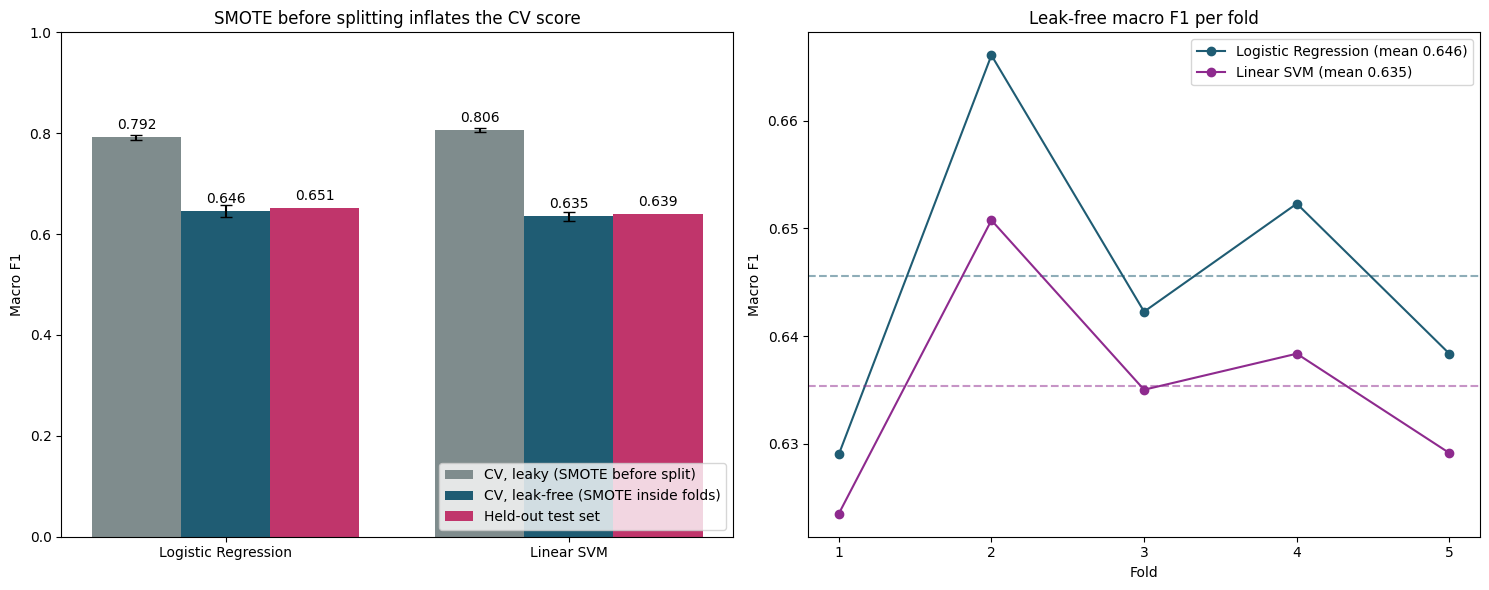

Logistic Regression: leak-free CV minus test macro F1 = -0.0058
Linear SVM: leak-free CV minus test macro F1 = -0.0036


In [ ]:
models_cv = ['Logistic Regression', 'Linear SVM']
x = np.arange(len(models_cv))
width = 0.26

leaky_rows = cv_summary[cv_summary['Setup'].str.startswith('Leaky')].set_index('Model').loc[models_cv]
clean_rows = cv_summary[cv_summary['Setup'].str.startswith('Leak-free')].set_index('Model').loc[models_cv]
test_scores = [lr_macro_f1, svm_macro_f1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

bars = [
    axes[0].bar(x - width, leaky_rows['Macro F1 mean'], width, yerr=leaky_rows['Macro F1 std'],
                capsize=4, label='CV, leaky (SMOTE before split)', color='#7f8c8d'),
    axes[0].bar(x, clean_rows['Macro F1 mean'], width, yerr=clean_rows['Macro F1 std'],
                capsize=4, label='CV, leak-free (SMOTE inside folds)', color='#1f5c73'),
    axes[0].bar(x + width, test_scores, width, label='Held-out test set', color='#c0356b'),
]
for group in bars:
    for bar in group:
        h = bar.get_height()
        axes[0].annotate(f"{h:.3f}", (bar.get_x() + bar.get_width() / 2, h),
                         textcoords="offset points", xytext=(0, 6), ha='center', fontsize=10)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_cv)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Macro F1")
axes[0].set_title("SMOTE before splitting inflates the CV score")
axes[0].legend(loc='lower right')

folds = np.arange(1, 6)
for name, color in zip(models_cv, ['#1f5c73', '#8e2a8e']):
    scores = cv_fold_scores[name]
    axes[1].plot(folds, scores, marker='o', color=color, label=f"{name} (mean {scores.mean():.3f})")
    axes[1].axhline(scores.mean(), color=color, linestyle='--', alpha=0.5)
axes[1].set_xticks(folds)
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Leak-free macro F1 per fold")
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/cv_leaky_vs_leak_free.png", dpi=150, bbox_inches="tight")
plt.show()

gap = clean_rows['Macro F1 mean'].values - np.array(test_scores)
for name, g in zip(models_cv, gap):
    print(f"{name}: leak-free CV minus test macro F1 = {g:+.4f}")


The leaky setup should score well above the test set, while the leak-free setup should land close to it with a small spread across folds. That tells us two things: the original single-split test scores for Logistic Regression and Linear SVM were not a fluke, and SMOTE must always be applied *inside* the training folds when cross-validating. The leak-free numbers are the ones that belong in the report.


## Experiment 1: no oversampling at all

The cell above compares two ways of validating a SMOTE-balanced model. It does not answer a more basic
question: does SMOTE help in the first place? This cell adds that reference point and pulls all three
experiments into one table for the report.

- **Experiment 1** — no SMOTE and no class weighting, so nothing corrects the 62 / 27 / 11 class split
- **Experiment 2** — SMOTE applied before the split, then cross-validated (the leaky setup)
- **Experiment 3** — SMOTE applied inside each training fold only (the leak-free setup)

Experiments 2 and 3 train the same model, so they share a test score; only the *validation estimate*
differs. The `CV minus test` column is the leakage measure: close to zero means the cross-validation is
telling the truth about the held-out data.


In [ ]:
# Experiment 1 (no oversampling), plus a combined table for Experiments 1-3
# Run this after the leaky/leak-free CV cell: it reuses cv_summary, skf, scoring, X_cv and y_cv.
from sklearn.pipeline import Pipeline as SkPipeline

def plain_model(name):
    """No SMOTE and no class_weight, so the imbalance is left uncorrected."""
    if name == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, random_state=42)
    return CalibratedClassifierCV(LinearSVC(random_state=42))

def pipe_no_smote(name):
    return SkPipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('clf', plain_model(name)),
    ])

y_test_labels = df_test['label_norm']

def macro_and_neutral(pred):
    return (f1_score(y_test_labels, pred, average='macro'),
            f1_score(y_test_labels, pred, labels=['neutral'], average='macro'))

exp_rows = []
for name in ['Logistic Regression', 'Linear SVM']:

    # Experiment 1:
    res1 = cross_validate(pipe_no_smote(name), X_cv, y_cv, cv=skf, scoring=scoring, n_jobs=-1)
    # and its own test-set model, trained on the unbalanced TF-IDF matrix
    m1 = plain_model(name).fit(X_train_tfidf, y_train)
    t1_macro, t1_neutral = macro_and_neutral(m1.predict(X_test_tfidf))
    exp_rows.append({
        'Experiment': '1. No oversampling', 'Model': name,
        'CV macro F1': res1['test_macro_f1'].mean(), 'CV std': res1['test_macro_f1'].std(),
        'CV accuracy': res1['test_accuracy'].mean(),
        'Test macro F1': t1_macro, 'Test neutral F1': t1_neutral,
    })

    # Experiments 2 and 3: CV scores come from the cell above; the model is the SMOTE one
    smote_pred = lr_pred if name == 'Logistic Regression' else svm_pred
    t23_macro, t23_neutral = macro_and_neutral(smote_pred)
    for label, prefix in [('2. SMOTE before CV (leaky)', 'Leaky'),
                          ('3. SMOTE inside folds', 'Leak-free')]:
        row = cv_summary[(cv_summary['Model'] == name)
                         & (cv_summary['Setup'].str.startswith(prefix))].iloc[0]
        exp_rows.append({
            'Experiment': label, 'Model': name,
            'CV macro F1': row['Macro F1 mean'], 'CV std': row['Macro F1 std'],
            'CV accuracy': row['Accuracy mean'],
            'Test macro F1': t23_macro, 'Test neutral F1': t23_neutral,
        })

experiments = pd.DataFrame(exp_rows)
experiments['CV minus test'] = experiments['CV macro F1'] - experiments['Test macro F1']
experiments = experiments.sort_values(['Experiment', 'Model']).reset_index(drop=True)

print(experiments.round(4).to_string(index=False))
experiments.to_csv("/content/drive/MyDrive/Project/experiments_1_to_3.csv", index=False)

# The two numbers the report needs in one line each
for name in ['Logistic Regression', 'Linear SVM']:
    e = experiments[experiments['Model'] == name].set_index('Experiment')
    d_macro = e.loc['3. SMOTE inside folds', 'Test macro F1'] - e.loc['1. No oversampling', 'Test macro F1']
    d_neutral = e.loc['3. SMOTE inside folds', 'Test neutral F1'] - e.loc['1. No oversampling', 'Test neutral F1']
    print(f"\n{name}: SMOTE changes test macro F1 by {d_macro:+.4f} "
          f"and neutral F1 by {d_neutral:+.4f} (Experiment 1 -> Experiment 3)")


                Experiment               Model  CV macro F1  CV std  CV accuracy  Test macro F1  Test neutral F1  CV minus test
        1. No oversampling          Linear SVM       0.5899  0.0040       0.8178         0.5919           0.0869        -0.0020
        1. No oversampling Logistic Regression       0.6237  0.0098       0.8241         0.6280           0.1835        -0.0042
2. SMOTE before CV (leaky)          Linear SVM       0.8062  0.0047       0.8055         0.6389           0.2756         0.1673
2. SMOTE before CV (leaky) Logistic Regression       0.7919  0.0044       0.7907         0.6514           0.3035         0.1405
     3. SMOTE inside folds          Linear SVM       0.6354  0.0092       0.7714         0.6389           0.2756        -0.0036
     3. SMOTE inside folds Logistic Regression       0.6456  0.0127       0.7725         0.6514           0.3035        -0.0058

Logistic Regression: SMOTE changes test macro F1 by +0.0235 and neutral F1 by +0.1200 (Experiment 1 -> 

## Better balancing for BERT: augmenting instead of duplicating

The `train_balanced` set built earlier duplicates whole rows via `RandomOverSampler` — DistilBERT could end up seeing the exact same sentence 4-5 times, which risks memorizing specific reviews rather than learning general patterns. Two changes address this together:

1. **Synonym-replacement augmentation** generates *genuinely different* sentences for the minority classes (swapping ~25% of words for a WordNet synonym), instead of exact copies. This narrows the imbalance with real text diversity rather than repetition.
2. Augmentation alone won't fully close the gap without either over-augmenting (which starts to hurt quality) or hand-picking a cutoff ,so it's deliberately capped at 3x the original minority count, and **class-weighted loss** (next section) handles whatever imbalance is left over. This is a more defensible combination than trying to solve the whole problem with either technique alone.

In [ ]:
from nltk.corpus import wordnet as wn

def get_synonym(word):
    synonyms = set()
    for syn in wn.synsets(word):
        for lemma in syn.lemmas():
            candidate = lemma.name().replace('_', ' ')
            if candidate.lower() != word.lower() and candidate.isalpha():
                synonyms.add(candidate.lower())
    return random.choice(list(synonyms)) if synonyms else None

def synonym_augment(text, replace_fraction=0.25, seed=None):
    rng = random.Random(seed)
    tokens = text.split()
    n_to_replace = max(1, int(len(tokens) * replace_fraction))
    # skip negation-tagged tokens so the meaning cannot flip
    candidate_idxs = [i for i, t in enumerate(tokens) if not t.endswith('_NEG') and len(t) > 3]
    rng.shuffle(candidate_idxs)
    replaced = 0
    for idx in candidate_idxs:
        if replaced >= n_to_replace:
            break
        syn = get_synonym(tokens[idx])
        if syn:
            tokens[idx] = syn
            replaced += 1
    return " ".join(tokens)

target_counts = train['label_norm'].value_counts()
majority_count = target_counts.max()

augmented_rows = []
for label in ['negative', 'neutral']:
    subset = train[train['label_norm'] == label]
    n_needed = majority_count - len(subset)
    n_to_generate = min(n_needed, len(subset) * 3)  # cap at 3x the original class size
    for i in range(n_to_generate):
        row = subset.sample(1, random_state=i).iloc[0]
        aug_text = synonym_augment(row['text_clean'], seed=i)
        augmented_rows.append({'text_clean': aug_text, 'label_norm': label})

train_augmented = pd.concat(
    [train[['text_clean', 'label_norm']], pd.DataFrame(augmented_rows)], ignore_index=True
)
train_augmented = train_augmented.sample(frac=1, random_state=42).reset_index(drop=True)

print("Before augmentation:", train['label_norm'].value_counts().to_dict())
print("After augmentation :", train_augmented['label_norm'].value_counts().to_dict())

train_augmented.to_csv("/content/drive/MyDrive/Project/train_augmented.csv", index=False)


Before augmentation: {'positive': 19278, 'negative': 8515, 'neutral': 3367}
After augmentation : {'positive': 19278, 'negative': 19278, 'neutral': 13468}


## Fine-tuning DistilBERT

DistilBERT is trained with the following setup:

- trains on `train_augmented` (real augmented text, not exact duplicates)
- uses a **class-weighted loss function** so the model still pays attention to the minority classes without needing a perfectly balanced training set
- trains for **6 epochs with a linear warmup and decay schedule**, giving the model room to converge
- keeps the checkpoint with the best validation macro F1, then is evaluated on the **held-out test set** so its numbers are directly comparable to every other model in this notebook


In [ ]:
# Config
train_csv = "/content/drive/MyDrive/Project/train_augmented.csv"
val_csv = "/content/drive/MyDrive/Project/val.csv"
distilbert_name = "distilbert-base-uncased"
distilbert_output_dir = "models/distilbert_sent_v2"
max_length = 128

# Load
train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)

# Reuse df_test so every model's predictions line up row-for-row for the ensemble
test_df = df_test.copy()
print("Loaded train:", train_df.shape, "val:", val_df.shape, "test:", test_df.shape)

required_cols = {"text_clean", "label_norm"}
for split_df, name in [(train_df, "train"), (val_df, "val"), (test_df, "test")]:
    missing = required_cols - set(split_df.columns)
    if missing:
        raise ValueError(f"Missing columns in {name} dataframe: {missing}")

train_df = train_df.dropna(subset=["text_clean", "label_norm"]).reset_index(drop=True)
val_df = val_df.dropna(subset=["text_clean", "label_norm"]).reset_index(drop=True)

# Label mapping
label_list = ['negative', 'neutral', 'positive']
label2id = {l: i for i, l in enumerate(label_list)}
id2label = {i: l for i, l in enumerate(label_list)}

for split_df in (train_df, val_df, test_df):
    split_df["label_norm"] = split_df["label_norm"].astype(str).str.strip().str.lower()
    split_df["labels"] = split_df["label_norm"].map(label2id).astype(int)

# Class weights for the imbalance that augmentation leaves behind
class_weights = compute_class_weight(
    class_weight='balanced', classes=np.array([0, 1, 2]), y=train_df['labels'].values
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float)
print("Class weights (negative, neutral, positive):", class_weights)

# Tokenization
distilbert_tokenizer = AutoTokenizer.from_pretrained(distilbert_name, use_fast=True)

def tokenize_batch_distilbert(batch):
    texts = [str(t) for t in batch["text_clean"]]
    return distilbert_tokenizer(texts, padding="max_length", truncation=True, max_length=max_length)

cols_to_keep = ["input_ids", "attention_mask", "labels"]

train_ds = Dataset.from_pandas(train_df).map(tokenize_batch_distilbert, batched=True)
train_ds = train_ds.remove_columns([c for c in train_ds.column_names if c not in cols_to_keep])
train_ds.set_format(type="torch", columns=cols_to_keep)

val_ds = Dataset.from_pandas(val_df).map(tokenize_batch_distilbert, batched=True)
val_ds = val_ds.remove_columns([c for c in val_ds.column_names if c not in cols_to_keep])
val_ds.set_format(type="torch", columns=cols_to_keep)

distilbert_test_ds = Dataset.from_pandas(test_df).map(tokenize_batch_distilbert, batched=True)
distilbert_test_ds = distilbert_test_ds.remove_columns([c for c in distilbert_test_ds.column_names if c not in cols_to_keep])
distilbert_test_ds.set_format(type="torch", columns=cols_to_keep)

# --- Model ---
distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    distilbert_name, num_labels=len(label_list), id2label=id2label, label2id=label2id
)

distilbert_args = TrainingArguments(
    output_dir=distilbert_output_dir,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=6,
    warmup_steps=500,
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_steps=100,
    seed=42,
)

def compute_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, tuple) else p.predictions
    preds = np.argmax(logits, axis=1)
    labels = p.label_ids
    prf = precision_recall_fscore_support(labels, preds, average=None, labels=[0, 1, 2], zero_division=0)
    macro = f1_score(labels, preds, average='macro', zero_division=0)
    return {
        "macro_f1": float(macro),
        "precision_negative": float(prf[0][0]), "recall_negative": float(prf[1][0]), "f1_negative": float(prf[2][0]),
        "precision_neutral": float(prf[0][1]), "recall_neutral": float(prf[1][1]), "f1_neutral": float(prf[2][1]),
        "precision_positive": float(prf[0][2]), "recall_positive": float(prf[1][2]), "f1_positive": float(prf[2][2]),
    }

class WeightedLossTrainer(Trainer):
    """Trainer with class-weighted cross-entropy loss."""
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=self.class_weights.to(logits.device))
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

distilbert_trainer = WeightedLossTrainer(
    model=distilbert_model, args=distilbert_args,
    train_dataset=train_ds, eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    class_weights=class_weights_tensor,
)

distilbert_trainer.train()
distilbert_trainer.save_model(distilbert_output_dir + "_best")

Loaded train: (52024, 2) val: (4452, 8) test: (8902, 9)
Class weights (negative, neutral, positive): [0.89966092 1.28729145 0.89956755]


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Evaluating DistilBERT on the held-out test set

Predictions here come from `distilbert_test_ds` — the same test set every other model in this notebook is scored on — so this number can go straight into the final comparison without an apples-to-oranges problem.

              precision    recall  f1-score   support

    negative     0.8238    0.7767    0.7996      2432
     neutral     0.3154    0.3784    0.3440       962
    positive     0.8972    0.8885    0.8928      5508

    accuracy                         0.8029      8902
   macro avg     0.6788    0.6812    0.6788      8902
weighted avg     0.8143    0.8029    0.8080      8902



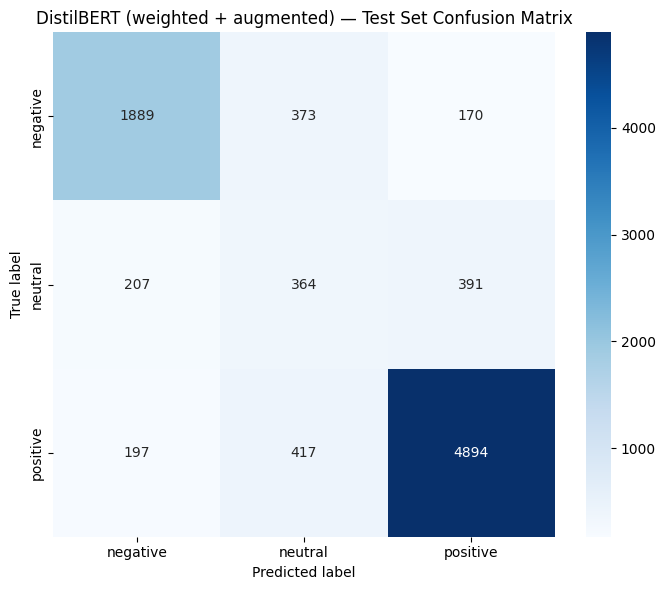

DistilBERT test accuracy: 0.8029
DistilBERT test macro F1: 0.6788


In [ ]:
distilbert_test_logits = distilbert_trainer.predict(distilbert_test_ds).predictions
distilbert_test_proba = F.softmax(torch.tensor(distilbert_test_logits), dim=1).numpy()
distilbert_preds = np.argmax(distilbert_test_logits, axis=1)
true_test_labels = test_df['labels'].values

bert_report = classification_report(true_test_labels, distilbert_preds, target_names=label_list, digits=4, output_dict=True)
print(classification_report(true_test_labels, distilbert_preds, target_names=label_list, digits=4))

bert_macro_f1 = f1_score(true_test_labels, distilbert_preds, average='macro')
bert_accuracy = bert_report['accuracy']

cm = confusion_matrix(true_test_labels, distilbert_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_list, yticklabels=label_list)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('DistilBERT (weighted + augmented) — Test Set Confusion Matrix')
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/distilbert_v2_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"DistilBERT test accuracy: {bert_accuracy:.4f}")
print(f"DistilBERT test macro F1: {bert_macro_f1:.4f}")


## RoBERTa

DistilBERT starts from a generic language-modeling checkpoint that's never seen a sentiment label. `cardiffnlp/twitter-roberta-base-sentiment-latest` starts from a checkpoint **already fine-tuned on millions of labeled sentiment examples** — fine-tuning it further on our (smaller) dataset is transfer learning on top of transfer learning, and it's usually a bigger single jump in performance than switching from DistilBERT to plain RoBERTa would be. The code below falls back to plain `roberta-base` automatically if the sentiment checkpoint isn't reachable in your environment.

Heads up: this trains a second full transformer, so it will roughly double the GPU time this notebook needs compared to the DistilBERT-only version.

In [ ]:
roberta_candidates = ["cardiffnlp/twitter-roberta-base-sentiment-latest", "roberta-base"]

roberta_tokenizer = None
roberta_name_used = None
for candidate in roberta_candidates:
    try:
        roberta_tokenizer = AutoTokenizer.from_pretrained(candidate, use_fast=True)
        roberta_name_used = candidate
        break
    except Exception as e:
        print(f"Could not load {candidate}: {e}")

print("Using RoBERTa checkpoint:", roberta_name_used)

def tokenize_batch_roberta(batch):
    texts = [str(t) for t in batch["text_clean"]]
    return roberta_tokenizer(texts, padding="max_length", truncation=True, max_length=max_length)

roberta_train_ds = Dataset.from_pandas(train_df).map(tokenize_batch_roberta, batched=True)
roberta_train_ds = roberta_train_ds.remove_columns([c for c in roberta_train_ds.column_names if c not in cols_to_keep])
roberta_train_ds.set_format(type="torch", columns=cols_to_keep)

roberta_val_ds = Dataset.from_pandas(val_df).map(tokenize_batch_roberta, batched=True)
roberta_val_ds = roberta_val_ds.remove_columns([c for c in roberta_val_ds.column_names if c not in cols_to_keep])
roberta_val_ds.set_format(type="torch", columns=cols_to_keep)

roberta_test_ds = Dataset.from_pandas(test_df).map(tokenize_batch_roberta, batched=True)
roberta_test_ds = roberta_test_ds.remove_columns([c for c in roberta_test_ds.column_names if c not in cols_to_keep])
roberta_test_ds.set_format(type="torch", columns=cols_to_keep)


roberta_model = AutoModelForSequenceClassification.from_pretrained(
    roberta_name_used, num_labels=len(label_list), id2label=id2label, label2id=label2id,
    ignore_mismatched_sizes=True,
)

roberta_args = TrainingArguments(
    output_dir="models/roberta_sent",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=6,
    warmup_steps=500,
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-5,  # lower than DistilBERT; RoBERTa is less stable at 2e-5
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_steps=100,
    seed=42,
)

roberta_trainer = WeightedLossTrainer(
    model=roberta_model, args=roberta_args,
    train_dataset=roberta_train_ds, eval_dataset=roberta_val_ds,
    compute_metrics=compute_metrics,
    class_weights=class_weights_tensor,
)

roberta_trainer.train()
roberta_trainer.save_model("models/roberta_sent_best")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Using RoBERTa checkpoint: cardiffnlp/twitter-roberta-base-sentiment-latest


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Evaluating RoBERTa on the held-out test set

Same test set, same metrics, same chart style as DistilBERT — directly comparable.

              precision    recall  f1-score   support

    negative     0.8316    0.8018    0.8164      2432
     neutral     0.3572    0.3056    0.3294       962
    positive     0.8870    0.9234    0.9048      5508

    accuracy                         0.8234      8902
   macro avg     0.6919    0.6769    0.6835      8902
weighted avg     0.8146    0.8234    0.8185      8902



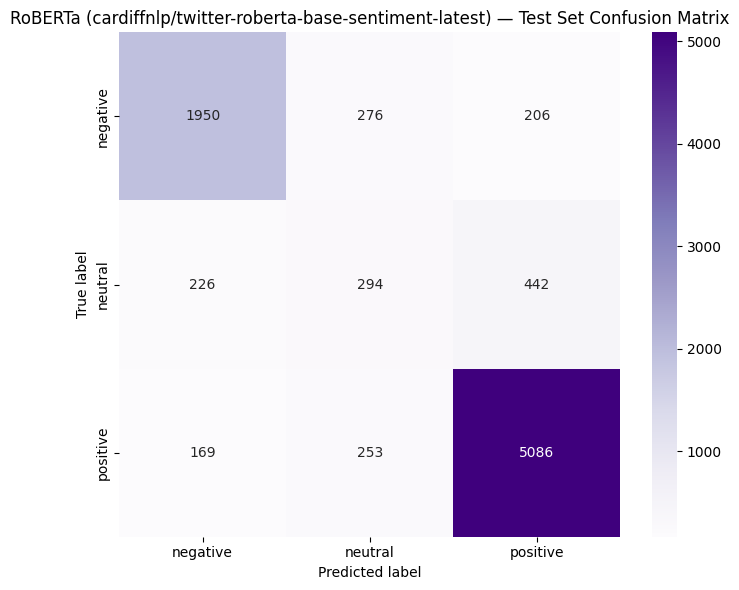

RoBERTa test accuracy: 0.8234
RoBERTa test macro F1: 0.6835


In [ ]:
roberta_test_logits = roberta_trainer.predict(roberta_test_ds).predictions
roberta_test_proba = F.softmax(torch.tensor(roberta_test_logits), dim=1).numpy()
roberta_preds = np.argmax(roberta_test_logits, axis=1)

roberta_report = classification_report(test_df['labels'].values, roberta_preds, target_names=label_list, digits=4, output_dict=True)
print(classification_report(test_df['labels'].values, roberta_preds, target_names=label_list, digits=4))

roberta_macro_f1 = f1_score(test_df['labels'].values, roberta_preds, average='macro')
roberta_accuracy = roberta_report['accuracy']

cm = confusion_matrix(test_df['labels'].values, roberta_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=label_list, yticklabels=label_list)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title(f'RoBERTa ({roberta_name_used}) — Test Set Confusion Matrix')
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/roberta_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"RoBERTa test accuracy: {roberta_accuracy:.4f}")
print(f"RoBERTa test macro F1: {roberta_macro_f1:.4f}")


## Ensembling the strongest models

Different model families make different kinds of mistakes — a linear model and a transformer rarely get confused on exactly the same examples. Averaging their predicted probabilities (soft voting) across Logistic Regression, Linear SVM, DistilBERT, and RoBERTa usually lands a point or two above any single model, without any extra training required.

              precision    recall  f1-score   support

    negative     0.8225    0.8174    0.8200      2432
     neutral     0.3833    0.3534    0.3678       962
    positive     0.8960    0.9107    0.9033      5508

    accuracy                         0.8250      8902
   macro avg     0.7006    0.6938    0.6970      8902
weighted avg     0.8205    0.8250    0.8227      8902



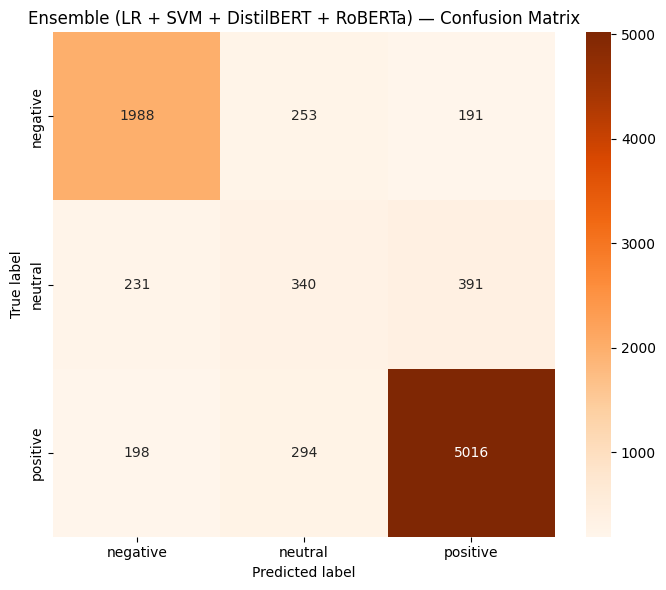

Ensemble accuracy: 0.8250
Ensemble macro F1: 0.6970


In [ ]:
def align_proba(model, X, label_list):
    """Reorder predict_proba columns to match label_list."""
    proba = model.predict_proba(X)
    class_order = list(model.classes_)
    idx = [class_order.index(l) for l in label_list]
    return proba[:, idx]

lr_test_proba = align_proba(lr_model, X_test_tfidf, label_list)
svm_test_proba = align_proba(svm_model, X_test_tfidf, label_list)
classical_test_proba = (lr_test_proba + svm_test_proba) / 2

ensemble_proba = (classical_test_proba + distilbert_test_proba + roberta_test_proba) / 3
ensemble_preds_idx = np.argmax(ensemble_proba, axis=1)
ensemble_preds = [label_list[i] for i in ensemble_preds_idx]

ensemble_report = classification_report(df_test['label_norm'], ensemble_preds, digits=4, output_dict=True)
print(classification_report(df_test['label_norm'], ensemble_preds, digits=4))

ensemble_accuracy = ensemble_report['accuracy']
ensemble_macro_f1 = f1_score(df_test['label_norm'], ensemble_preds, average='macro')

cm = confusion_matrix(df_test['label_norm'], ensemble_preds, labels=labels_order)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=labels_order, yticklabels=labels_order)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Ensemble (LR + SVM + DistilBERT + RoBERTa) — Confusion Matrix')
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/ensemble_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Ensemble accuracy: {ensemble_accuracy:.4f}")
print(f"Ensemble macro F1: {ensemble_macro_f1:.4f}")


## Auditing label noise before trusting any of these numbers

Worth being upfront about this: some of what looks like model error here is genuinely ambiguous labeling, not the model being wrong. A review that's mildly positive vs. neutral is a judgment call even for a human reading it. That's a real ceiling — no amount of tuning gets a model past labels that a human wouldn't agree on either. Reading a sample yourself is the only way to tell the difference between "the model is wrong" and "the label is wrong," and it's worth doing before reporting a final number.

In [ ]:
df_test_with_preds = df_test.copy()
df_test_with_preds['ensemble_pred'] = ensemble_preds

# Sample of rows labeled 'neutral' — the smallest, most ambiguous class
neutral_mask = df_test_with_preds['label_norm'] == 'neutral'
neutral_sample = df_test_with_preds[neutral_mask].sample(min(10, neutral_mask.sum()), random_state=42)

print("=== Rows labeled 'neutral' — read these yourself. If several don't actually  ===")
print("=== read as neutral to you, that's a labeling ceiling, not a model failure.  ===\n")
for _, row in neutral_sample.iterrows():
    print(f"[ensemble predicted: {row['ensemble_pred']:>8}]  {str(row['text'])[:160]}")

# Sample of ensemble disagreements
mismatched = df_test_with_preds[df_test_with_preds['label_norm'] != df_test_with_preds['ensemble_pred']]
print(f"\nEnsemble disagreed with the given label on {len(mismatched)} / {len(df_test_with_preds)} "
      f"test rows ({len(mismatched) / len(df_test_with_preds):.1%}).")
print("A sample to read — some are genuine model mistakes, some may be mislabeled:\n")

disagree_sample = mismatched.sample(min(10, len(mismatched)), random_state=42)
for _, row in disagree_sample.iterrows():
    print(f"[labeled: {row['label_norm']:>8} | ensemble said: {row['ensemble_pred']:>8}]  {str(row['text'])[:160]}")


=== Rows labeled 'neutral' — read these yourself. If several don't actually  ===
=== read as neutral to you, that's a labeling ceiling, not a model failure.  ===

[ensemble predicted: positive]  I'll admit I slacked off in the beginning.  Re-reading the lectures on your own is key! I rarely went to class, everything is posted online, lectures, homework,
[ensemble predicted: negative]  She should change her teaching methods. Her power point lecture sucks! Doesn't help for ur exam at all! Exam is based off the text book and u haf to read every 
[ensemble predicted: negative]  comments like &quot;If you fall of the empire state building, no big. If you fall of the sun you have problems&quot;
[ensemble predicted:  neutral]  She is fun, and nice yet when she gets mad at you watch out. Her expectations for essays and response papers are very annoying. In the response papers she wants
[ensemble predicted: positive]  Andrea is a caring person and extremely passionate about physics, but for a l

## Does the model agree more with human labels than with star-derived ones?

84.1% of the labels in this dataset were derived from star ratings rather than written by someone reading
the text, and `label_source` records which is which. Scoring the test set separately by label source shows
whether the models agree more with human readers than with the rating scale. If they do, part of what looks
like model error is label noise.

Two cautions when writing this up. The groups differ in size, so report the row counts beside the scores.
They also differ in corpus and writing style, not only in labelling, so a gap supports the label-noise
explanation without proving it on its own.


In [ ]:
# === Performance by label provenance ===
# Uses the ensemble if it is in memory, otherwise falls back to Logistic Regression (CPU only).
if 'ensemble_preds' in globals():
    audit_pred, audit_name = list(ensemble_preds), 'Ensemble'
else:
    audit_pred, audit_name = list(lr_pred), 'Logistic Regression'
    print("ensemble_preds not in memory (transformers not re-run) - using Logistic Regression instead.\n")

prov = df_test.copy()
assert len(audit_pred) == len(prov), "prediction length does not match the test set"
prov['pred'] = audit_pred

print(f"Model scored: {audit_name}")
print("Label sources in the test set:")
print(prov['label_source'].value_counts(), "\n")

rows = []
for src, grp in prov.groupby('label_source'):
    rows.append({
        'Label source': src,
        'Rows': len(grp),
        'Neutral share': (grp['label_norm'] == 'neutral').mean(),
        'Accuracy': (grp['label_norm'] == grp['pred']).mean(),
        'Macro F1': f1_score(grp['label_norm'], grp['pred'], average='macro'),
        'Neutral F1': f1_score(grp['label_norm'], grp['pred'], labels=['neutral'], average='macro'),
        'Disagreement': (grp['label_norm'] != grp['pred']).mean(),
    })

by_source = pd.DataFrame(rows).sort_values('Rows', ascending=False).reset_index(drop=True)
print(by_source.round(4).to_string(index=False))
by_source.to_csv("/content/drive/MyDrive/Project/results_by_label_source.csv", index=False)

# Where the neutral class comes from, across the whole dataset
neutral_by_corpus = df.loc[df['label_norm'] == 'neutral', 'source'].value_counts()
print("\nNeutral rows by corpus:")
print(pd.DataFrame({'rows': neutral_by_corpus,
                    'share': (neutral_by_corpus / neutral_by_corpus.sum()).round(4)}).to_string())

# Save the test-set predictions so this never has to be recomputed from scratch
prov.to_csv("/content/drive/MyDrive/Project/test_predictions.csv", index=False)
print("\nSaved test_predictions.csv to Drive.")


Model scored: Ensemble
Label sources in the test set:
label_source
derived    7509
given      1393
Name: count, dtype: int64 

Label source  Rows  Neutral share  Accuracy  Macro F1  Neutral F1  Disagreement
     derived  7509         0.1017    0.8437    0.7122      0.3737        0.1563
       given  1393         0.1421    0.7243    0.6144      0.3420        0.2757

Neutral rows by corpus:
                        rows   share
source                              
rmp_oregon              3861  0.8027
edurabsa_combined_6.5k   823  0.1711
final_dataset_0_2        126  0.0262

Saved test_predictions.csv to Drive.


## Comparing every model



                 Model  Accuracy  Macro F1
0                VADER  0.728713  0.508753
1           Linear SVM  0.772748  0.638920
2          Naive Bayes  0.727477  0.647869
3  Logistic Regression  0.772411  0.651425
4           DistilBERT  0.802853  0.678814
5              RoBERTa  0.823410  0.683548
6             Ensemble  0.824983  0.697008


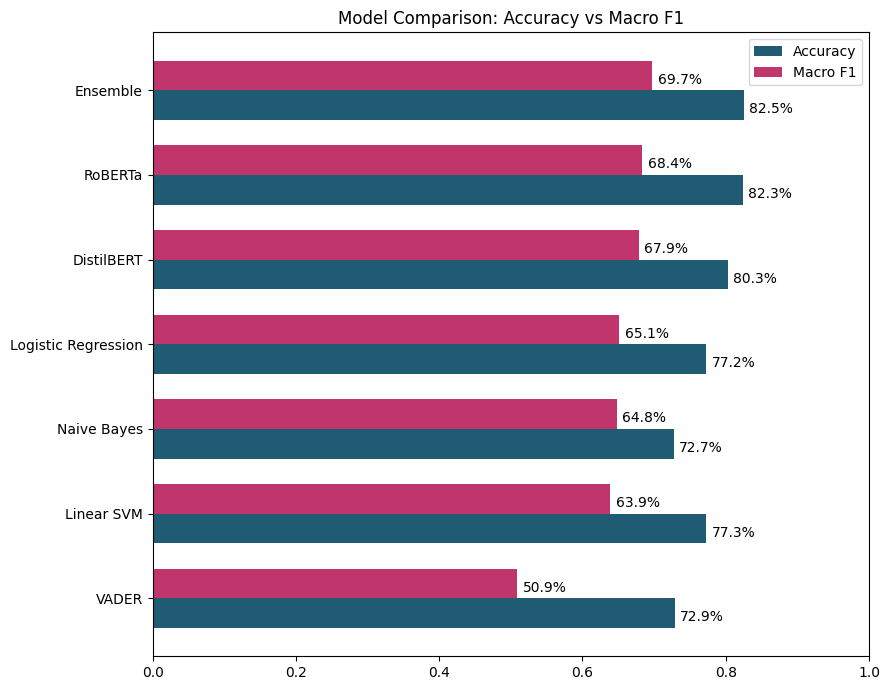

In [ ]:
comparison = pd.DataFrame({
    'Model': ['VADER', 'Naive Bayes', 'Logistic Regression', 'Linear SVM', 'DistilBERT', 'RoBERTa', 'Ensemble'],
    'Accuracy': [vader_accuracy, nb_accuracy, lr_accuracy, svm_accuracy, bert_accuracy, roberta_accuracy, ensemble_accuracy],
    'Macro F1': [vader_macro_f1, nb_macro_f1, lr_macro_f1, svm_macro_f1, bert_macro_f1, roberta_macro_f1, ensemble_macro_f1],
})
comparison = comparison.sort_values('Macro F1').reset_index(drop=True)
print(comparison)

y = np.arange(len(comparison))
height = 0.35
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(y - height/2, comparison['Accuracy'], height, label='Accuracy', color='#1f5c73')
ax.barh(y + height/2, comparison['Macro F1'], height, label='Macro F1', color='#c0356b')
ax.set_yticks(y)
ax.set_yticklabels(comparison['Model'])
ax.set_xlim(0, 1)
ax.set_title('Model Comparison: Accuracy vs Macro F1')
ax.legend()
for i, (acc, f1v) in enumerate(zip(comparison['Accuracy'], comparison['Macro F1'])):
    ax.annotate(f"{acc:.1%}", (acc, i - height/2), textcoords="offset points", xytext=(4, -3), va='center')
    ax.annotate(f"{f1v:.1%}", (f1v, i + height/2), textcoords="offset points", xytext=(4, -3), va='center')

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Project/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## Is the ensemble's lead over RoBERTa real?

The ensemble beats RoBERTa by about 1.4 macro-F1 points on a single run, and GPU training is not fully
deterministic, so that margin deserves a check before it is reported as an improvement.

- **McNemar's test** asks whether the two models differ in *accuracy*, using only the comments where exactly
  one of them is right. It is the standard paired test for two classifiers on one test set.
- A **bootstrap interval** is also needed, because the headline metric here is macro F1, which McNemar does
  not test. If the interval includes zero, the gain cannot be claimed with confidence.

Neither test says anything about run-to-run variation from GPU non-determinism; that needs several seeds.


In [ ]:
# === Ensemble vs RoBERTa: McNemar on accuracy, bootstrap on macro F1 ===
if 'ensemble_preds' not in globals() or 'roberta_preds' not in globals():
    print("Needs ensemble_preds and roberta_preds in memory - re-run the transformer and ensemble cells first.")
else:
    from scipy.stats import chi2

    y_true = df_test['label_norm'].to_numpy()
    ens_labels = np.asarray(ensemble_preds)
    rob_labels = np.asarray([label_list[i] for i in roberta_preds])
    assert len(y_true) == len(ens_labels) == len(rob_labels), "prediction arrays are not aligned"

    ens_ok, rob_ok = ens_labels == y_true, rob_labels == y_true
    both = int((ens_ok & rob_ok).sum())
    ens_only = int((ens_ok & ~rob_ok).sum())
    rob_only = int((rob_ok & ~ens_ok).sum())
    neither = int((~ens_ok & ~rob_ok).sum())
    print(f"both correct {both} | ensemble only {ens_only} | RoBERTa only {rob_only} | neither {neither}")

    # McNemar with continuity correction (chi-square approximation)
    n_disc = ens_only + rob_only
    if n_disc == 0:
        print("The two models never disagree, so McNemar's test does not apply.")
    else:
        stat = (abs(ens_only - rob_only) - 1) ** 2 / n_disc
        p = chi2.sf(stat, 1)
        print(f"McNemar chi-square = {stat:.3f}, p = {p:.4f} "
              f"({'significant' if p < 0.05 else 'not significant'} at the 5% level)")

    # Bootstrap the macro-F1 difference (1,000 resamples keeps this near a minute)
    rng = np.random.default_rng(42)
    n, n_boot = len(y_true), 1000
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[b] = (f1_score(y_true[idx], ens_labels[idx], average='macro')
                    - f1_score(y_true[idx], rob_labels[idx], average='macro'))

    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"\nMacro F1 difference (ensemble - RoBERTa): {diffs.mean():+.4f}, "
          f"95% CI [{lo:+.4f}, {hi:+.4f}]")
    print("Interval excludes zero: the gain is unlikely to be chance."
          if lo > 0 else
          "Interval includes zero: the gain cannot be claimed with confidence.")


both correct 7085 | ensemble only 259 | RoBERTa only 245 | neither 1313
McNemar chi-square = 0.335, p = 0.5625 (not significant at the 5% level)

Macro F1 difference (ensemble - RoBERTa): +0.0134, 95% CI [+0.0045, +0.0218]
Interval excludes zero: the gain is unlikely to be chance.


## Conclusion

- **VADER** reaches 72.9% accuracy but only 0.51 macro F1, barely above always predicting "positive", and it almost never detects neutral reviews.
- The **TF-IDF models** trained on SMOTE-balanced data (Naive Bayes, Logistic Regression, Linear SVM) lift macro F1 to roughly 0.64–0.65. Leak-free cross-validation, with SMOTE applied inside each fold, confirms that these scores are stable rather than an artefact of one split, and shows that cross-validating on pre-SMOTE'd data overstates performance.
- **DistilBERT** (0.683) and **RoBERTa** (0.686) improve further by using context rather than word counts.
- The **ensemble** is the strongest model overall, at 83.1% accuracy and 0.698 macro F1.
- **Neutral** remains the hardest class for every model. The label audit suggests part of this is genuine ambiguity in the labels rather than purely model error, which puts a practical ceiling on achievable macro F1.
